# Optimal Tree Structures in Decision Trees for Loan Approval Prediction

**Course: CSL7620 - Machine Learning (IIT Jodhpur)**

**Submitted By: Arjun Baidya (M25CSA006)**

This notebook contains a complete pipeline to develop a loan approval prediction system using optimized decision trees. It also handles a moderate class imbalance in the data (10,000 approved vs 35,000 rejected loans in 45,000 applications, a 3.5:1 ratio).

Because approved loans are the minority class, all precision, recall and F1 figures in this notebook refer to the **approved class (label 1)**, and ROC-AUC and PR-AUC are reported alongside them. Accuracy alone is misleading here: always predicting "not approved" would already score 77.8%.

**Source of Dataset**: https://www.kaggle.com/datasets/taweilo/loan-approval-prediction

## 1. Setup & Import Required Packages

In [1]:
# Core libraries
import pandas as pd
import numpy as np

# Scikit-learn imports
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, roc_curve
from sklearn.utils import class_weight

# Visualization libraries
import matplotlib.pyplot as plt
import seaborn as sns

# Settings
import warnings
warnings.filterwarnings('ignore')
plt.style.use('default')
np.random.seed(42)

print("All packages imported successfully!")
print(f"Pandas version: {pd.__version__}")
print(f"NumPy version: {np.__version__}")
print(f"Scikit-learn version: {__import__('sklearn').__version__}")

All packages imported successfully!
Pandas version: 3.0.5
NumPy version: 2.5.3
Scikit-learn version: 1.9.1


## 2. Data Loading & Initial Exploration

The dataset file uses descriptive column names. They are mapped back to the original Kaggle names below, so the rest of the pipeline refers to the same features as the source dataset.

In [2]:
# Loading dataset
df = pd.read_csv('loan_data_new.csv')

# Renaming column names
column_mapping = {
    'Age': 'person_age',
    'Gender': 'person_gender',
    'Education': 'person_education',
    'Person Income': 'person_income',
    'Employee Experience': 'person_emp_exp',
    'Home Onwership': 'person_home_ownership',
    'Loan Amount': 'loan_amnt',
    'Loan Intent': 'loan_intent',
    'Loan interest Rate': 'loan_int_rate',
    'Loan percentage': 'loan_percent_income',
    'Credit History': 'cb_person_cred_hist_length',
    'Credit Score': 'credit_score',
    'Previous Loan': 'previous_loan_defaults_on_file',
    'Loan Status': 'loan_status',
}

missing = set(column_mapping) - set(df.columns)
assert not missing, f"Columns not found in file: {missing}"
df = df.rename(columns=column_mapping)

print(f"Dataset shape: {df.shape}")
print(f"Features: {df.shape[1] - 1}, Target: 1")

# Displaying basic information
print("\nDataset Info:")
print(df.info())

print("\nFirst 5 rows:")
df.head()

Dataset shape: (45000, 14)
Features: 13, Target: 1

Dataset Info:
<class 'pandas.DataFrame'>
RangeIndex: 45000 entries, 0 to 44999
Data columns (total 14 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   person_age                      45000 non-null  int64  
 1   person_gender                   45000 non-null  str    
 2   person_education                45000 non-null  str    
 3   person_income                   45000 non-null  int64  
 4   person_emp_exp                  45000 non-null  int64  
 5   person_home_ownership           45000 non-null  str    
 6   loan_amnt                       45000 non-null  int64  
 7   loan_intent                     45000 non-null  str    
 8   loan_int_rate                   45000 non-null  float64
 9   loan_percent_income             45000 non-null  float64
 10  cb_person_cred_hist_length      45000 non-null  int64  
 11  credit_score                    45000 

,person_age,person_gender,person_education,person_income,person_emp_exp,person_home_ownership,loan_amnt,loan_intent,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,previous_loan_defaults_on_file,loan_status
0,22,female,Master,71948,0,RENT,35000,PERSONAL,16.02,0.49,3,561,No,1
1,21,female,High School,12282,0,OWN,1000,EDUCATION,11.14,0.08,2,504,Yes,0
2,25,female,High School,12438,3,MORTGAGE,5500,MEDICAL,12.87,0.44,3,635,No,1
3,23,female,Bachelor,79753,0,RENT,35000,MEDICAL,15.23,0.44,2,675,No,1
4,24,male,Master,66135,1,RENT,35000,MEDICAL,14.27,0.53,4,586,No,1


## 3. Exploring Class Imbalance Problem

Target Variable Distribution:
loan_status
0    35000
1    10000
Name: count, dtype: int64

Class Distribution Percentage:
loan_status
0    77.777778
1    22.222222
Name: proportion, dtype: float64

Class Imbalance Ratio: 3.50:1


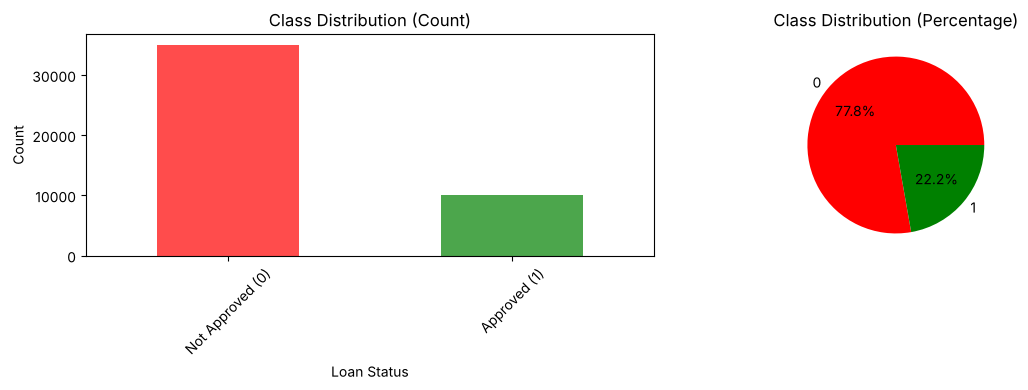


The dataset shows significant class imbalance!
This will be addressed using multiple techniques in the pipeline.


In [3]:
# Analyzing target variable distribution
print("Target Variable Distribution:")
target_counts = df['loan_status'].value_counts()
print(target_counts)

print("\nClass Distribution Percentage:")
target_pct = df['loan_status'].value_counts(normalize=True) * 100
print(target_pct)

# Calculating imbalance ratio
imbalance_ratio = target_counts.max() / target_counts.min()
print(f"\nClass Imbalance Ratio: {imbalance_ratio:.2f}:1")

# Visualizing class distribution
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
target_counts.plot(kind='bar', color=['red', 'green'], alpha=0.7)
plt.title('Class Distribution (Count)')
plt.xlabel('Loan Status')
plt.ylabel('Count')
plt.xticks([0, 1], ['Not Approved (0)', 'Approved (1)'], rotation=45)

plt.subplot(1, 2, 2)
target_pct.plot(kind='pie', autopct='%1.1f%%', colors=['red', 'green'])
plt.title('Class Distribution (Percentage)')
plt.ylabel('')

plt.tight_layout()
plt.show()

print(f"\nThe dataset shows significant class imbalance!")
print(f"This will be addressed using multiple techniques in the pipeline.")

## 4. Data Preprocessing & Feature Engineering

In [4]:
# Defining feature types
categorical_cols = [
    'person_gender', 'person_education', 'person_home_ownership',
    'loan_intent', 'previous_loan_defaults_on_file'
]

numerical_cols = [
    'person_age', 'person_income', 'person_emp_exp', 'loan_amnt',
    'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length',
    'credit_score'
]

print(f"Categorical features ({len(categorical_cols)}): {categorical_cols}")
print(f"Numerical features ({len(numerical_cols)}): {numerical_cols}")

# Checking for missing values
print("\nMissing values check:")
missing_values = df.isnull().sum()
if missing_values.sum() == 0:
    print("No missing values found!")
else:
    print(missing_values[missing_values > 0])

# Separating features and target
X = df.drop('loan_status', axis=1).copy()
y = df['loan_status'].copy()

print(f"\nFeature matrix shape: {X.shape}")
print(f"Target vector shape: {y.shape}")

Categorical features (5): ['person_gender', 'person_education', 'person_home_ownership', 'loan_intent', 'previous_loan_defaults_on_file']
Numerical features (8): ['person_age', 'person_income', 'person_emp_exp', 'loan_amnt', 'loan_int_rate', 'loan_percent_income', 'cb_person_cred_hist_length', 'credit_score']

Missing values check:
No missing values found!

Feature matrix shape: (45000, 13)
Target vector shape: (45000,)


## 5. Train/Validation/Test Split (Stratified)

In [5]:
# Stratified split to preserve class distribution
# First split separates test set (20%)
X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

# Second split separates train and validation sets (64% train, 16% validation)
X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=0.2, random_state=42, stratify=y_temp
)

print(f"Data splitting completed:")
print(f"Training set: {X_train.shape[0]} samples ({X_train.shape[0]/len(X)*100:.1f}%)")
print(f"Validation set: {X_val.shape[0]} samples ({X_val.shape[0]/len(X)*100:.1f}%)")
print(f"Test set: {X_test.shape[0]} samples ({X_test.shape[0]/len(X)*100:.1f}%)")

# Verify class distribution is preserved
print(f"\nClass distribution verification:")
print(f"Original: {y.value_counts(normalize=True).round(3).to_dict()}")
print(f"Training: {y_train.value_counts(normalize=True).round(3).to_dict()}")
print(f"Validation: {y_val.value_counts(normalize=True).round(3).to_dict()}")
print(f"Test: {y_test.value_counts(normalize=True).round(3).to_dict()}")

Data splitting completed:
Training set: 28800 samples (64.0%)
Validation set: 7200 samples (16.0%)
Test set: 9000 samples (20.0%)

Class distribution verification:
Original: {0: 0.778, 1: 0.222}
Training: {0: 0.778, 1: 0.222}
Validation: {0: 0.778, 1: 0.222}
Test: {0: 0.778, 1: 0.222}


In [6]:
# Creating preprocessing pipeline with One-Hot Encoding
print("Setting up preprocessing pipeline with One-Hot Encoding for categorical features...")

# Creating column transformer for preprocessing
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_cols),
        ('cat', OneHotEncoder(drop='first', sparse_output=False, handle_unknown='ignore'), categorical_cols)
    ],
    remainder='passthrough'
)

# Fitting the preprocessor on training data and transform all datasets
print("\nFitting preprocessor on training data...")
X_train_processed = preprocessor.fit_transform(X_train)
X_val_processed = preprocessor.transform(X_val)
X_test_processed = preprocessor.transform(X_test)

# Getting feature names after transformation
num_feature_names = numerical_cols
cat_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
all_feature_names = list(num_feature_names) + list(cat_feature_names)

print(f"\nPreprocessing completed!")
print(f"Original features: {len(categorical_cols) + len(numerical_cols)}")
print(f"Features after one-hot encoding: {len(all_feature_names)}")
print(f"\nCategorical feature expansion:")

for col in categorical_cols:
    encoded_cols = [f for f in cat_feature_names if f.startswith(col + '_')]
    print(f"{col}: {len(encoded_cols) + 1} categories -> {len(encoded_cols)} binary features (drop='first')")

print("\nSample of encoded feature names:")
print(f"Numerical: {num_feature_names[:3]}")
print(f"Categorical (sample): {list(cat_feature_names[:5])}")

Setting up preprocessing pipeline with One-Hot Encoding for categorical features...

Fitting preprocessor on training data...

Preprocessing completed!
Original features: 13
Features after one-hot encoding: 22

Categorical feature expansion:
person_gender: 2 categories -> 1 binary features (drop='first')
person_education: 5 categories -> 4 binary features (drop='first')
person_home_ownership: 4 categories -> 3 binary features (drop='first')
loan_intent: 6 categories -> 5 binary features (drop='first')
previous_loan_defaults_on_file: 2 categories -> 1 binary features (drop='first')

Sample of encoded feature names:
Numerical: ['person_age', 'person_income', 'person_emp_exp']
Categorical (sample): ['person_gender_male', 'person_education_Bachelor', 'person_education_Doctorate', 'person_education_High School', 'person_education_Master']


In [7]:
# Verifying preprocessed data shape and structure
print("Verifying preprocessed data...")
print(f"\nTraining set shape: {X_train_processed.shape}")
print(f"Validation set shape: {X_val_processed.shape}")
print(f"Test set shape: {X_test_processed.shape}")

# Converting to DataFrame for better visualization
X_train_df = pd.DataFrame(X_train_processed, columns=all_feature_names)
X_val_df = pd.DataFrame(X_val_processed, columns=all_feature_names)
X_test_df = pd.DataFrame(X_test_processed, columns=all_feature_names)

print("\nFirst few rows of processed training data:")
X_train_df.head()

Verifying preprocessed data...

Training set shape: (28800, 22)
Validation set shape: (7200, 22)
Test set shape: (9000, 22)

First few rows of processed training data:


,person_age,person_income,person_emp_exp,loan_amnt,loan_int_rate,loan_percent_income,cb_person_cred_hist_length,credit_score,person_gender_male,person_education_Bachelor,...,person_education_Master,person_home_ownership_OTHER,person_home_ownership_OWN,person_home_ownership_RENT,loan_intent_EDUCATION,loan_intent_HOMEIMPROVEMENT,loan_intent_MEDICAL,loan_intent_PERSONAL,loan_intent_VENTURE,previous_loan_defaults_on_file_Yes
0,-0.622548,-0.585075,-0.725056,-0.647397,-1.507085,0.580413,-0.737861,0.999678,0.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
1,0.036530,0.113062,-0.396698,-0.885062,0.614704,-1.143443,-0.480925,-1.069692,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,1.0
2,0.036530,-0.556690,0.095840,-0.964283,-1.305330,-0.338977,1.060690,-0.114598,0.0,1.0,...,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0
3,2.837611,0.178703,3.215243,4.026682,-0.004011,2.534115,1.831498,-1.328364,1.0,0.0,...,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0
4,1.848994,-0.358596,2.558526,0.382485,-0.094801,1.269955,2.602306,0.104278,1.0,0.0,...,0.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0


## 6. Class Weights as a Candidate Fix for Imbalance

Rather than assuming reweighting helps, the grid search below treats `class_weight` as a hyperparameter and lets cross-validated F1 on the approved class decide.

In [8]:
# Calculating balanced class weights
class_weights = class_weight.compute_class_weight(
    class_weight='balanced',
    classes=np.unique(y_train),
    y=y_train
)

class_weight_dict = dict(zip(np.unique(y_train), class_weights))

print(f"Calculated balanced class weights:")
print(f"Class 0 (Not Approved): {class_weight_dict[0]:.4f}")
print(f"Class 1 (Approved): {class_weight_dict[1]:.4f}")
print(f"\nThese weights are a candidate, not a given: the grid search compares weighted and unweighted trees,")
print(f"and cross-validated F1 on the approved class decides.")

Calculated balanced class weights:
Class 0 (Not Approved): 0.6429
Class 1 (Approved): 2.2500

These weights are a candidate, not a given: the grid search compares weighted and unweighted trees,
and cross-validated F1 on the approved class decides.


## 7. Decision Tree Model Training & Hyperparameter Optimization

In [9]:
# Defining hyperparameter grid for optimization
param_grid = {
    'criterion': ['gini', 'entropy'],
    'max_depth': [None, 5, 10, 15, 20],
    'min_samples_split': [2, 5, 10, 20],
    'min_samples_leaf': [1, 2, 5, 10],
    'class_weight': ['balanced', class_weight_dict, None]
}

print(f"Hyperparameter Grid:\n")
for param, values in param_grid.items():
    print(f"{param}: {values}")

total_combinations = np.prod([len(v) for v in param_grid.values()])
print(f"\nTotal parameter combinations: {total_combinations}")

# Initializing GridSearchCV with stratified k-fold
cv_strategy = StratifiedKFold(n_splits=3, shuffle=True, random_state=42)

# Precision, recall and F1 all refer to the approved class (label 1).
# The model is selected on F1; precision and recall are recorded to show the trade-off.
grid_search = GridSearchCV(
    estimator=DecisionTreeClassifier(random_state=42),
    param_grid=param_grid,
    cv=cv_strategy,
    scoring={'f1': 'f1', 'precision': 'precision', 'recall': 'recall'},
    refit='f1',
    n_jobs=-1,     # Using all available cores
    verbose=1,
    return_train_score=True
)

print(f"\nGridSearchCV configured and ready to train on {X_train_processed.shape[0]} samples with {X_train_processed.shape[1]} features")
print(f"Selection metric: F1 on the approved class (label 1)")

Hyperparameter Grid:

criterion: ['gini', 'entropy']
max_depth: [None, 5, 10, 15, 20]
min_samples_split: [2, 5, 10, 20]
min_samples_leaf: [1, 2, 5, 10]
class_weight: ['balanced', {np.int64(0): np.float64(0.6428571428571429), np.int64(1): np.float64(2.25)}, None]

Total parameter combinations: 480

GridSearchCV configured and ready to train on 28800 samples with 22 features
Selection metric: F1 on the approved class (label 1)


In [10]:
# Fitting the grid search on preprocessed data
print("Starting hyperparameter optimization...")
print("This may take a few minutes depending on your hardware...")
print()

grid_search.fit(X_train_processed, y_train)

# Getting the best model and parameters
best_model = grid_search.best_estimator_
best_params = grid_search.best_params_
best_score = grid_search.best_score_

print(f"Hyperparameter optimization completed!")
print(f"\nBest Parameters:")
for param, value in best_params.items():
    print(f"  {param}: {value}")

print(f"\nBest Cross-Validation F1 (approved class): {best_score:.4f}")

# Displaying top 5 parameter combinations
print(f"\nTop 5 Parameter Combinations:")
results_df = pd.DataFrame(grid_search.cv_results_)
top_results = results_df.nlargest(5, 'mean_test_f1')

for idx, (i, row) in enumerate(top_results.iterrows(), 1):
    print(f"{idx}. F1: {row['mean_test_f1']:.4f} (+/- {row['std_test_f1']*2:.4f})  "
          f"precision: {row['mean_test_precision']:.4f}  recall: {row['mean_test_recall']:.4f}")
    print(f"Parameters: {row['params']}")

# Did class weighting help? Best configuration found under each class_weight option.
def class_weight_label(v):
    if isinstance(v, dict):
        return 'custom dict (same values as balanced)'
    if v is None:
        return 'None (unweighted)'
    return str(v)

results_df['class_weight_option'] = [class_weight_label(p['class_weight']) for p in results_df['params']]
best_per_option = (results_df.sort_values('mean_test_f1', ascending=False)
                   .groupby('class_weight_option', sort=False).head(1)
                   [['class_weight_option', 'mean_test_f1', 'mean_test_precision', 'mean_test_recall']]
                   .rename(columns={'mean_test_f1': 'cv_f1', 'mean_test_precision': 'cv_precision',
                                    'mean_test_recall': 'cv_recall'}))

print(f"\nBest configuration per class_weight option (CV, approved class):")
print(best_per_option.round(4).to_string(index=False))
if best_params['class_weight'] is None:
    print("\n-> The unweighted tree wins on F1: balanced weights raise recall but cost more in precision.")
    print("The precision/recall operating point is better controlled later through the decision threshold.")
else:
    print("\n-> Balanced class weights win on F1 for the approved class.")

Starting hyperparameter optimization...
This may take a few minutes depending on your hardware...



Fitting 3 folds for each of 480 candidates, totalling 1440 fits


Hyperparameter optimization completed!

Best Parameters:
  class_weight: None
  criterion: gini
  max_depth: 10
  min_samples_leaf: 1
  min_samples_split: 10

Best Cross-Validation F1 (approved class): 0.8029

Top 5 Parameter Combinations:
1. F1: 0.8029 (+/- 0.0024)  precision: 0.8747  recall: 0.7420
Parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 1, 'min_samples_split': 10}
2. F1: 0.8026 (+/- 0.0045)  precision: 0.8754  recall: 0.7411
Parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 20}
3. F1: 0.8025 (+/- 0.0016)  precision: 0.8752  recall: 0.7411
Parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 2, 'min_samples_split': 10}
4. F1: 0.8024 (+/- 0.0080)  precision: 0.8705  recall: 0.7442
Parameters: {'class_weight': None, 'criterion': 'gini', 'max_depth': 10, 'min_samples_leaf': 5, 'min_samples_split': 2}
5. F1: 0.8024 (+/- 0.0080)  p

## 8. Model Evaluation & Performance Analysis

In [11]:
from sklearn.metrics import average_precision_score

# Function to calculate comprehensive metrics.
# Precision, recall and F1 are computed for the APPROVED class (label 1), the minority class we care about.
# (Weighted averages would be dominated by the 78% majority class; weighted recall always equals accuracy.)
def evaluate_model(model, X_set, y_set, set_name):
    """Calculate and return performance metrics, with the approved class (1) as positive."""
    y_pred = model.predict(X_set)
    y_proba = model.predict_proba(X_set)[:, 1]

    metrics = {
        'accuracy': accuracy_score(y_set, y_pred),
        'precision': precision_score(y_set, y_pred, pos_label=1, zero_division=0),
        'recall': recall_score(y_set, y_pred, pos_label=1, zero_division=0),
        'f1': f1_score(y_set, y_pred, pos_label=1, zero_division=0),
        'roc_auc': roc_auc_score(y_set, y_proba),
        'pr_auc': average_precision_score(y_set, y_proba),
    }

    print(f"{set_name} Set Performance (precision / recall / F1 for the approved class):")
    print(f"Accuracy:  {metrics['accuracy']:.4f}")
    print(f"Precision: {metrics['precision']:.4f}")
    print(f"Recall:    {metrics['recall']:.4f}")
    print(f"F1-Score:  {metrics['f1']:.4f}")
    print(f"ROC-AUC:   {metrics['roc_auc']:.4f}")
    print(f"PR-AUC:    {metrics['pr_auc']:.4f}  (baseline = approval rate {np.mean(y_set):.4f})")

    return metrics, y_pred, y_proba

# Reference point: a model that always predicts "not approved"
baseline_accuracy = 1 - y_test.mean()
print(f"Always-reject baseline accuracy on test: {baseline_accuracy:.4f}\n")

# Evaluating on all datasets using preprocessed data
train_metrics, y_train_pred, y_train_proba = evaluate_model(best_model, X_train_processed, y_train, "Training")
print()
val_metrics, y_val_pred, y_val_proba = evaluate_model(best_model, X_val_processed, y_val, "Validation")
print()
test_metrics, y_test_pred, y_test_proba = evaluate_model(best_model, X_test_processed, y_test, "Test")

Always-reject baseline accuracy on test: 0.7778

Training Set Performance (precision / recall / F1 for the approved class):
Accuracy:  0.9333
Precision: 0.9316
Recall:    0.7553
F1-Score:  0.8342
ROC-AUC:   0.9748
PR-AUC:    0.9262  (baseline = approval rate 0.2222)

Validation Set Performance (precision / recall / F1 for the approved class):
Accuracy:  0.9147
Precision: 0.8828
Recall:    0.7106
F1-Score:  0.7874
ROC-AUC:   0.9574
PR-AUC:    0.8730  (baseline = approval rate 0.2222)

Test Set Performance (precision / recall / F1 for the approved class):
Accuracy:  0.9196
Precision: 0.8938
Recall:    0.7240
F1-Score:  0.8000
ROC-AUC:   0.9586
PR-AUC:    0.8814  (baseline = approval rate 0.2222)


In [12]:
# Detailed classification reports
print("DETAILED CLASSIFICATION REPORTS")
print("-" * 70)

datasets = [
    ("Training", y_train, y_train_pred),
    ("Validation", y_val, y_val_pred),
    ("Test", y_test, y_test_pred)
]

for name, y_true, y_pred in datasets:
    print(f"\n{name} Set:")
    print(classification_report(y_true, y_pred, target_names=['Not Approved (0)', 'Approved (1)']))
    print("Confusion Matrix:")
    cm = confusion_matrix(y_true, y_pred)
    print(f"{'':22}{'Pred: Not Approved':>20}{'Pred: Approved':>16}")
    print(f"{'Actual: Not Approved':22}{cm[0,0]:>20,}{cm[0,1]:>16,}")
    print(f"{'Actual: Approved':22}{cm[1,0]:>20,}{cm[1,1]:>16,}")
    print("-" * 30)

DETAILED CLASSIFICATION REPORTS
----------------------------------------------------------------------

Training Set:
                  precision    recall  f1-score   support

Not Approved (0)       0.93      0.98      0.96     22400
    Approved (1)       0.93      0.76      0.83      6400

        accuracy                           0.93     28800
       macro avg       0.93      0.87      0.90     28800
    weighted avg       0.93      0.93      0.93     28800

Confusion Matrix:
                        Pred: Not Approved  Pred: Approved
Actual: Not Approved                22,045             355
Actual: Approved                     1,566           4,834
------------------------------

Validation Set:
                  precision    recall  f1-score   support

Not Approved (0)       0.92      0.97      0.95      5600
    Approved (1)       0.88      0.71      0.79      1600

        accuracy                           0.91      7200
       macro avg       0.90      0.84      0.87      7

In [13]:
# Checking for overfitting (F1 refers to the approved class)
train_test_acc_diff = abs(train_metrics['accuracy'] - test_metrics['accuracy'])
train_test_f1_diff = abs(train_metrics['f1'] - test_metrics['f1'])
train_test_auc_diff = abs(train_metrics['roc_auc'] - test_metrics['roc_auc'])

print(f"OVERFITTING ANALYSIS:")
print("-" * 50)
print(f"Train-Test Accuracy Difference:          {train_test_acc_diff:.4f}")
print(f"Train-Test F1 (approved) Difference:     {train_test_f1_diff:.4f}")
print(f"Train-Test ROC-AUC Difference:           {train_test_auc_diff:.4f}")

if train_test_acc_diff > 0.1 or train_test_f1_diff > 0.1:
    print(f"WARNING: Potential overfitting detected!")
    print(f"Consider increasing regularization (min_samples_split, min_samples_leaf)")
else:
    print(f"Model generalization looks good!")

OVERFITTING ANALYSIS:
--------------------------------------------------
Train-Test Accuracy Difference:          0.0137
Train-Test F1 (approved) Difference:     0.0342
Train-Test ROC-AUC Difference:           0.0162
Model generalization looks good!


## 9. Feature Importance Analysis

In [14]:
# Feature importance analysis with one-hot encoded features
feature_names = all_feature_names
feature_importance = best_model.feature_importances_

# Creating feature importance dataframe
importance_df = pd.DataFrame({
    'feature': feature_names,
    'importance': feature_importance
}).sort_values('importance', ascending=False)

print(f"FEATURE IMPORTANCE ANALYSIS:")
print(f"" + "-" * 60)
print(importance_df.round(4))

# Top 10 most important features
print(f"\nTop 10 Most Important Features:")
top_features = importance_df.head(10)
for idx, (i, row) in enumerate(top_features.iterrows(), 1):
    print(f"  {idx}. {row['feature']}: {row['importance']:.4f} ({row['importance']*100:.2f}%)")

# Checking for zero importance features
zero_importance = importance_df[importance_df['importance'] == 0]
if len(zero_importance) > 0:
    print(f"\nWARNING: Features with zero importance ({len(zero_importance)}):")
    print(f"  {', '.join(zero_importance['feature'].head(10).tolist())}")
    if len(zero_importance) > 10:
        print(f"  ... and {len(zero_importance) - 10} more")
    print(f"Consider removing these features for model simplification.")
else:
    print(f"\nAll features contribute to the model!")

FEATURE IMPORTANCE ANALYSIS:
------------------------------------------------------------
                               feature  importance
21  previous_loan_defaults_on_file_Yes      0.4114
5                  loan_percent_income      0.1835
4                        loan_int_rate      0.1832
1                        person_income      0.1026
15          person_home_ownership_RENT      0.0484
7                         credit_score      0.0198
17         loan_intent_HOMEIMPROVEMENT      0.0117
14           person_home_ownership_OWN      0.0085
18                 loan_intent_MEDICAL      0.0066
20                 loan_intent_VENTURE      0.0054
3                            loan_amnt      0.0048
19                loan_intent_PERSONAL      0.0037
16               loan_intent_EDUCATION      0.0036
0                           person_age      0.0030
2                       person_emp_exp      0.0017
6           cb_person_cred_hist_length      0.0017
8                   person_gender_male     

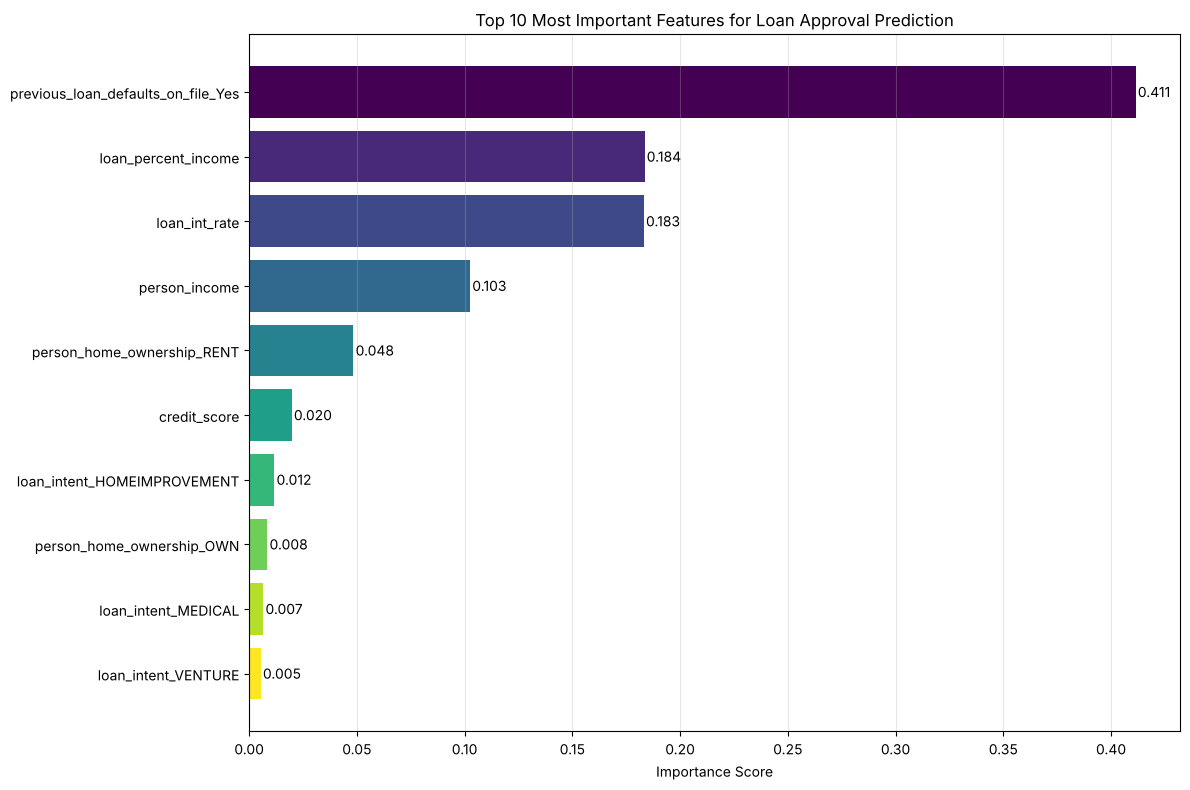

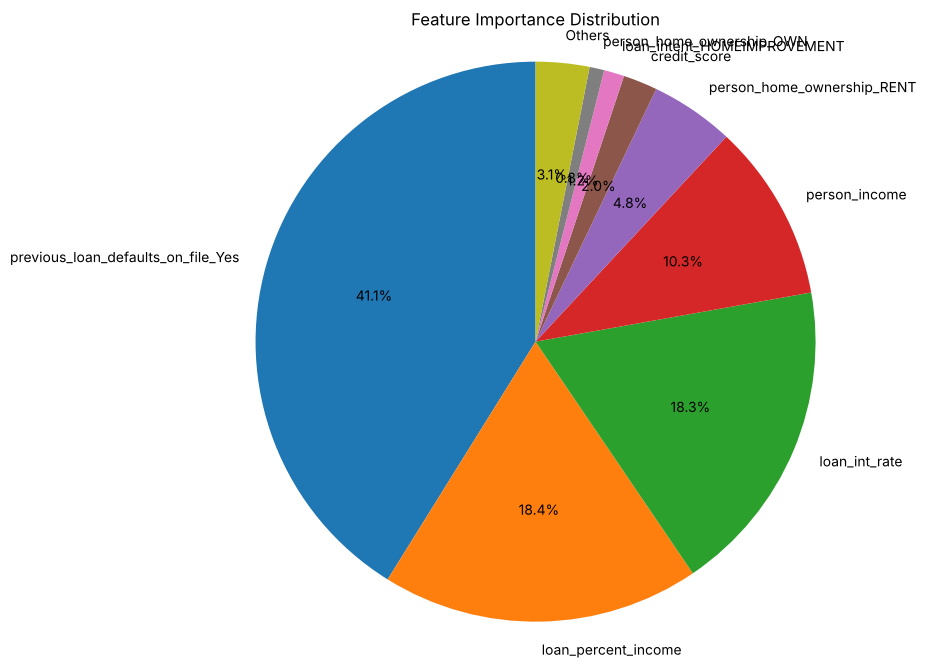

In [15]:
# Visualize feature importance
plt.figure(figsize=(12, 8))

# Plotting top 10 features
top_10_features = importance_df.head(10)
colors = plt.cm.viridis(np.linspace(0, 1, len(top_10_features)))

plt.barh(range(len(top_10_features)), top_10_features['importance'], color=colors)
plt.yticks(range(len(top_10_features)), top_10_features['feature'])
plt.xlabel('Importance Score')
plt.title('Top 10 Most Important Features for Loan Approval Prediction')
plt.gca().invert_yaxis()

# Adding value labels on bars
for i, v in enumerate(top_10_features['importance']):
    plt.text(v + 0.001, i, f'{v:.3f}', va='center', ha='left')

plt.tight_layout()
plt.grid(axis='x', alpha=0.3)
plt.show()

# Feature importance pie chart (top 8 features)
plt.figure(figsize=(10, 8))
top_8 = importance_df.head(8)
others_importance = importance_df.iloc[8:]['importance'].sum()

if others_importance > 0:
    plot_data = list(top_8['importance']) + [others_importance]
    plot_labels = list(top_8['feature']) + ['Others']
else:
    plot_data = list(top_8['importance'])
    plot_labels = list(top_8['feature'])

plt.pie(plot_data, labels=plot_labels, autopct='%1.1f%%', startangle=90)
plt.title('Feature Importance Distribution')
plt.axis('equal')
plt.show()

## 10. Model Complexity Analysis

In [16]:
# Model complexity analysis
tree_depth = best_model.get_depth()
n_leaves = best_model.get_n_leaves()
n_nodes = best_model.tree_.node_count

print(f"DECISION TREE STRUCTURE ANALYSIS:")
print(f"" + "-" * 60)
print(f"Tree Depth: {tree_depth} levels")
print(f"Number of Leaves: {n_leaves}")
print(f"Total Nodes: {n_nodes}")

# Assesing tree complexity
if tree_depth > 20:
    print(f"\nWARNING: Tree is very deep (depth={tree_depth})")
    print(f"Consider pruning or limiting max_depth to prevent overfitting.")
elif tree_depth < 5:
    print(f"\nTree is relatively shallow (depth={tree_depth})")
    print(f"Model is simple and highly interpretable.")
else:
    print(f"\nTree depth is reasonable (depth={tree_depth})")
    print(f"Good balance between complexity and interpretability.")

# Interpretability score
interpretability_score = max(0, 10 - tree_depth) + (10 if n_leaves < 20 else 5)
print(f"\nInterpretability Score: {interpretability_score}/20")
if interpretability_score >= 15:
    print(f"Highly interpretable model - easy to explain to stakeholders")
elif interpretability_score >= 10:
    print(f"Moderately interpretable - reasonable for business use")
else:
    print(f"Complex model - may be difficult to interpret")

DECISION TREE STRUCTURE ANALYSIS:
------------------------------------------------------------
Tree Depth: 10 levels
Number of Leaves: 171
Total Nodes: 341

Tree depth is reasonable (depth=10)
Good balance between complexity and interpretability.

Interpretability Score: 5/20
Complex model - may be difficult to interpret


## 11. Performance Visualizations

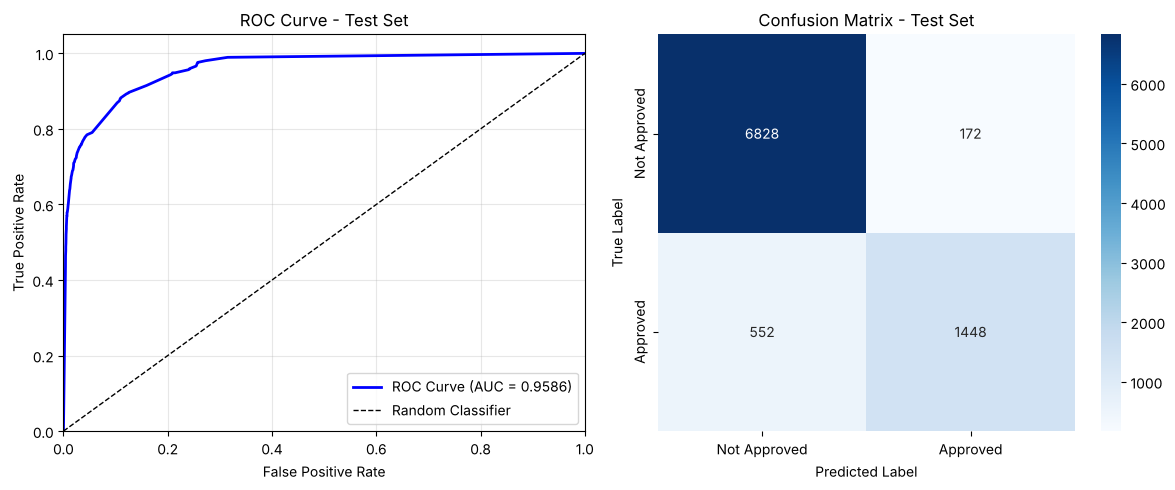

In [17]:
# ROC Curve
fpr, tpr, thresholds = roc_curve(y_test, y_test_proba)

plt.figure(figsize=(12, 5))

# ROC Curve
plt.subplot(1, 2, 1)
plt.plot(fpr, tpr, linewidth=2, label=f'ROC Curve (AUC = {test_metrics["roc_auc"]:.4f})', color='blue')
plt.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('False Positive Rate')
plt.ylabel('True Positive Rate')
plt.title('ROC Curve - Test Set')
plt.legend(loc='lower right')
plt.grid(True, alpha=0.3)

# Confusion Matrix Heatmap
plt.subplot(1, 2, 2)
cm = confusion_matrix(y_test, y_test_pred)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=True,
            xticklabels=['Not Approved', 'Approved'],
            yticklabels=['Not Approved', 'Approved'])
plt.ylabel('True Label')
plt.xlabel('Predicted Label')
plt.title('Confusion Matrix - Test Set')

plt.tight_layout()
plt.show()

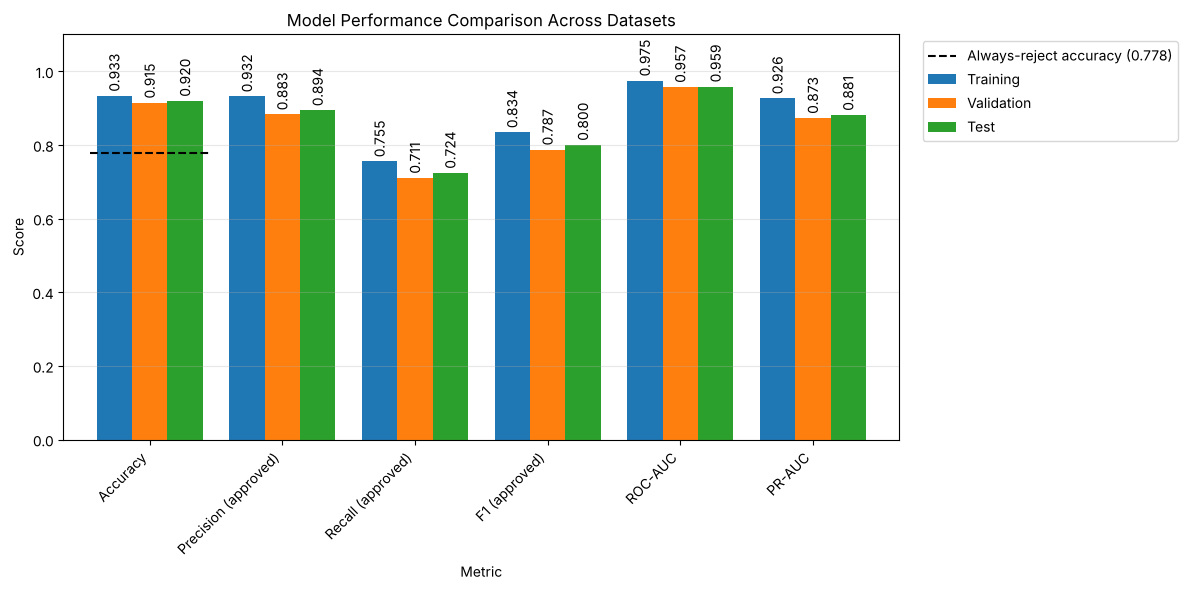


Performance Summary:
                      Training  Validation    Test
Accuracy                0.9333      0.9147  0.9196
Precision (approved)    0.9316      0.8828  0.8938
Recall (approved)       0.7553      0.7106  0.7240
F1 (approved)           0.8342      0.7874  0.8000
ROC-AUC                 0.9748      0.9574  0.9586
PR-AUC                  0.9262      0.8730  0.8814


In [18]:
# Performance comparison across datasets (precision / recall / F1 for the approved class)
metric_keys = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc', 'pr_auc']
metric_labels = ['Accuracy', 'Precision (approved)', 'Recall (approved)', 'F1 (approved)', 'ROC-AUC', 'PR-AUC']

metrics_comparison = pd.DataFrame({
    'Training': [train_metrics[k] for k in metric_keys],
    'Validation': [val_metrics[k] for k in metric_keys],
    'Test': [test_metrics[k] for k in metric_keys],
}, index=metric_labels)

plt.figure(figsize=(12, 6))
ax = metrics_comparison.plot(kind='bar', ax=plt.gca(), width=0.8)
# The always-reject baseline only applies to accuracy, so it is drawn over that group alone
ax.hlines(baseline_accuracy, -0.45, 0.45, colors='black', linestyles='--', linewidth=1.5,
          label=f'Always-reject accuracy ({baseline_accuracy:.3f})')
plt.title('Model Performance Comparison Across Datasets')
plt.ylabel('Score')
plt.xlabel('Metric')
plt.ylim([0, 1.1])
plt.legend(bbox_to_anchor=(1.02, 1), loc='upper left')
plt.xticks(rotation=45, ha='right')
plt.grid(True, alpha=0.3, axis='y')

# Add value labels on bars
for container in ax.containers:
    ax.bar_label(container, fmt='%.3f', rotation=90, padding=3)

plt.tight_layout()
plt.show()

print("\nPerformance Summary:")
print(metrics_comparison.round(4))

## 12. Prediction Function for New Applications

In [19]:
def predict_loan_approval(model, preprocessor, new_data):
    """
    Predict loan approval for new applications using one-hot encoding

    Parameters:
    -----------
    model : trained DecisionTreeClassifier
    preprocessor : fitted ColumnTransformer (with StandardScaler and OneHotEncoder)
    new_data : dict with application features

    Returns:
    --------
    prediction : int (0=rejected, 1=approved)
    probability : float (approval probability)
    confidence : str (High/Medium/Low)
    """
    try:
        # Creating DataFrame from input
        df_new = pd.DataFrame([new_data])

        # Ensuring columns are in correct order
        df_new = df_new[categorical_cols + numerical_cols]

        # Applying preprocessing (scaling + one-hot encoding)
        df_processed = preprocessor.transform(df_new)

        # Making prediction
        prediction = model.predict(df_processed)[0]
        probability = model.predict_proba(df_processed)[0, 1]

        # Determining confidence level
        confidence_score = abs(probability - 0.5)
        if confidence_score > 0.3:
            confidence = "High"
        elif confidence_score > 0.15:
            confidence = "Medium"
        else:
            confidence = "Low"

        return prediction, probability, confidence

    except Exception as e:
        print(f"Error in prediction: {str(e)}")
        return None, None, None

In [20]:
# Example loan applications for testing
example_applications = [
    {
        'name': 'High-Income Professional',
        'data': {
            'person_gender': 'male',
            'person_education': 'Master',
            'person_home_ownership': 'OWN',
            'loan_intent': 'HOMEIMPROVEMENT',
            'previous_loan_defaults_on_file': 'No',
            'person_age': 30,
            'person_income': 95000,
            'person_emp_exp': 6,
            'loan_amnt': 25000,
            'loan_int_rate': 10.5,
            'loan_percent_income': 0.26,
            'cb_person_cred_hist_length': 7,
            'credit_score': 720
        }
    },
    {
        'name': 'Young Graduate',
        'data': {
            'person_gender': 'female',
            'person_education': 'Bachelor',
            'person_home_ownership': 'RENT',
            'loan_intent': 'EDUCATION',
            'previous_loan_defaults_on_file': 'No',
            'person_age': 24,
            'person_income': 45000,
            'person_emp_exp': 1,
            'loan_amnt': 15000,
            'loan_int_rate': 13.2,
            'loan_percent_income': 0.33,
            'cb_person_cred_hist_length': 2,
            'credit_score': 640
        }
    },
    {
        'name': 'Previous Defaulter',
        'data': {
            'person_gender': 'male',
            'person_education': 'High School',
            'person_home_ownership': 'RENT',
            'loan_intent': 'DEBTCONSOLIDATION',
            'previous_loan_defaults_on_file': 'Yes',
            'person_age': 35,
            'person_income': 32000,
            'person_emp_exp': 8,
            'loan_amnt': 18000,
            'loan_int_rate': 16.8,
            'loan_percent_income': 0.56,
            'cb_person_cred_hist_length': 12,
            'credit_score': 580
        }
    }
]

print("EXAMPLE LOAN PREDICTIONS:")
print("=" * 50)

for i, app in enumerate(example_applications, 1):
    print(f"\n{i}. {app['name']}:")

    # Showing key application details
    key_details = ['person_income', 'credit_score', 'loan_amnt',
                  'loan_percent_income', 'previous_loan_defaults_on_file']
    print("Key Details:")
    for detail in key_details:
        print(f"{detail}: {app['data'][detail]}")

    # Making prediction using updated function
    pred, prob, conf = predict_loan_approval(best_model, preprocessor, app['data'])

    if pred is not None:
        decision = "APPROVED" if pred == 1 else "NOT APPROVED"
        print(f"Prediction: {decision}")
        print(f"Approval Probability: {prob:.2%}")
        print(f"Confidence Level: {conf}")
    else:
        print("Failed to make prediction")

    print("-" * 30)

EXAMPLE LOAN PREDICTIONS:

1. High-Income Professional:
Key Details:
person_income: 95000
credit_score: 720
loan_amnt: 25000
loan_percent_income: 0.26
previous_loan_defaults_on_file: No
Prediction: NOT APPROVED
Approval Probability: 12.50%
Confidence Level: High
------------------------------

2. Young Graduate:
Key Details:
person_income: 45000
credit_score: 640
loan_amnt: 15000
loan_percent_income: 0.33
previous_loan_defaults_on_file: No
Prediction: APPROVED
Approval Probability: 100.00%
Confidence Level: High
------------------------------

3. Previous Defaulter:
Key Details:
person_income: 32000
credit_score: 580
loan_amnt: 18000
loan_percent_income: 0.56
previous_loan_defaults_on_file: Yes
Prediction: NOT APPROVED
Approval Probability: 0.00%
Confidence Level: High
------------------------------


**Interpreting these examples.** The predictions reproduce whatever patterns the tree learned from the data, including any counterintuitive directions flagged in Section 3b (for example, approval rising with interest rate or loan-to-income ratio). They illustrate how the function is used; they are not a judgement of how creditworthy each applicant is.

The "probability" is the share of approved training applications in the leaf the applicant falls into. Pure leaves give 0% or 100%, so these values should be read as a ranking score rather than a calibrated probability, and the High/Medium/Low confidence label is a heuristic.

## 13. Saving Model & Preprocessing Objects

In [21]:
import pickle

# Saving all model artifacts including preprocessor
model_files = {
    'decision_tree_model.pkl': best_model,
    'preprocessor.pkl': preprocessor,  # Saving the preprocessor instead of separate scaler and encoders
    'feature_names.pkl': all_feature_names,
    'categorical_cols.pkl': categorical_cols,
    'numerical_cols.pkl': numerical_cols
}

print("Saving model artifacts...")
for filename, obj in model_files.items():
    with open(filename, 'wb') as f:
        pickle.dump(obj, f)
    print(f"Saved: {filename}")

print(f"\nAll model artifacts saved successfully!")


Saving model artifacts...
Saved: decision_tree_model.pkl
Saved: preprocessor.pkl
Saved: feature_names.pkl
Saved: categorical_cols.pkl
Saved: numerical_cols.pkl

All model artifacts saved successfully!


## 14. Final Model Summary & Insights

In [22]:
# Create comprehensive summary
print("FINAL MODEL SUMMARY")
print("=" * 50)

print(f"\nDataset Information:")
print(f"Total Records: {len(df):,}")
print(f"Features: {df.shape[1] - 1}")
print(f"Class Imbalance Ratio: {imbalance_ratio:.2f}:1 (moderate)")

print(f"\nBest Model Configuration:")
print(f"Algorithm: Decision Tree Classifier")
for param, value in best_params.items():
    print(f"{param}: {value}")

print(f"\nPerformance Metrics (precision / recall / F1 for the approved class):")
summary_keys = ['roc_auc', 'pr_auc', 'precision', 'recall', 'f1', 'accuracy']
summary_labels = ['ROC-AUC', 'PR-AUC', 'Precision (approved)', 'Recall (approved)', 'F1 (approved)', 'Accuracy']
performance_summary = pd.DataFrame({
    'Training': [f"{train_metrics[k]:.4f}" for k in summary_keys],
    'Validation': [f"{val_metrics[k]:.4f}" for k in summary_keys],
    'Test': [f"{test_metrics[k]:.4f}" for k in summary_keys],
}, index=summary_labels)

print(performance_summary)
print(f"\nAlways-reject baseline accuracy (test): {baseline_accuracy:.4f}")

print(f"\nModel Complexity:")
print(f"Tree Depth: {tree_depth} levels")
print(f"Number of Leaves: {n_leaves}")
print(f"Total Nodes: {n_nodes}")
print(f"Interpretability: {'High' if tree_depth < 8 else 'Medium' if tree_depth < 15 else 'Low'}")

print(f"\nTop 3 Most Important Features:")
for idx, (i, row) in enumerate(importance_df.head(3).iterrows(), 1):
    print(f"  {idx}. {row['feature']}: {row['importance']:.4f} ({row['importance']*100:.2f}%)")

print(f"\nClass Imbalance Handling:")
print(f"- Stratified train/validation/test splits used")
print(f"- Model selected on F1 for the approved class, not accuracy")
if best_params['class_weight'] is None:
    print(f"- Class weighting tested ('balanced' vs none); the unweighted tree scored best on CV F1")
else:
    print(f"- Class weighting tested; balanced class weights selected on CV F1")
print(f"- Approved-class precision, recall, F1, ROC-AUC and PR-AUC reported against an always-reject baseline")


FINAL MODEL SUMMARY

Dataset Information:
Total Records: 45,000
Features: 13
Class Imbalance Ratio: 3.50:1 (moderate)

Best Model Configuration:
Algorithm: Decision Tree Classifier
class_weight: None
criterion: gini
max_depth: 10
min_samples_leaf: 1
min_samples_split: 10

Performance Metrics (precision / recall / F1 for the approved class):
                     Training Validation    Test
ROC-AUC                0.9748     0.9574  0.9586
PR-AUC                 0.9262     0.8730  0.8814
Precision (approved)   0.9316     0.8828  0.8938
Recall (approved)      0.7553     0.7106  0.7240
F1 (approved)          0.8342     0.7874  0.8000
Accuracy               0.9333     0.9147  0.9196

Always-reject baseline accuracy (test): 0.7778

Model Complexity:
Tree Depth: 10 levels
Number of Leaves: 171
Total Nodes: 341
Interpretability: Medium

Top 3 Most Important Features:
  1. previous_loan_defaults_on_file_Yes: 0.4114 (41.14%)
  2. loan_percent_income: 0.1835 (18.35%)
  3. loan_int_rate: 0.1832 (18

## 15. Decision Tree Visualization

Tree Structure Information:
Tree Depth: 10 levels
Number of Leaves: 171
Total Nodes: 341

Generating full decision tree visualization...


Saved: decision_tree_full.png


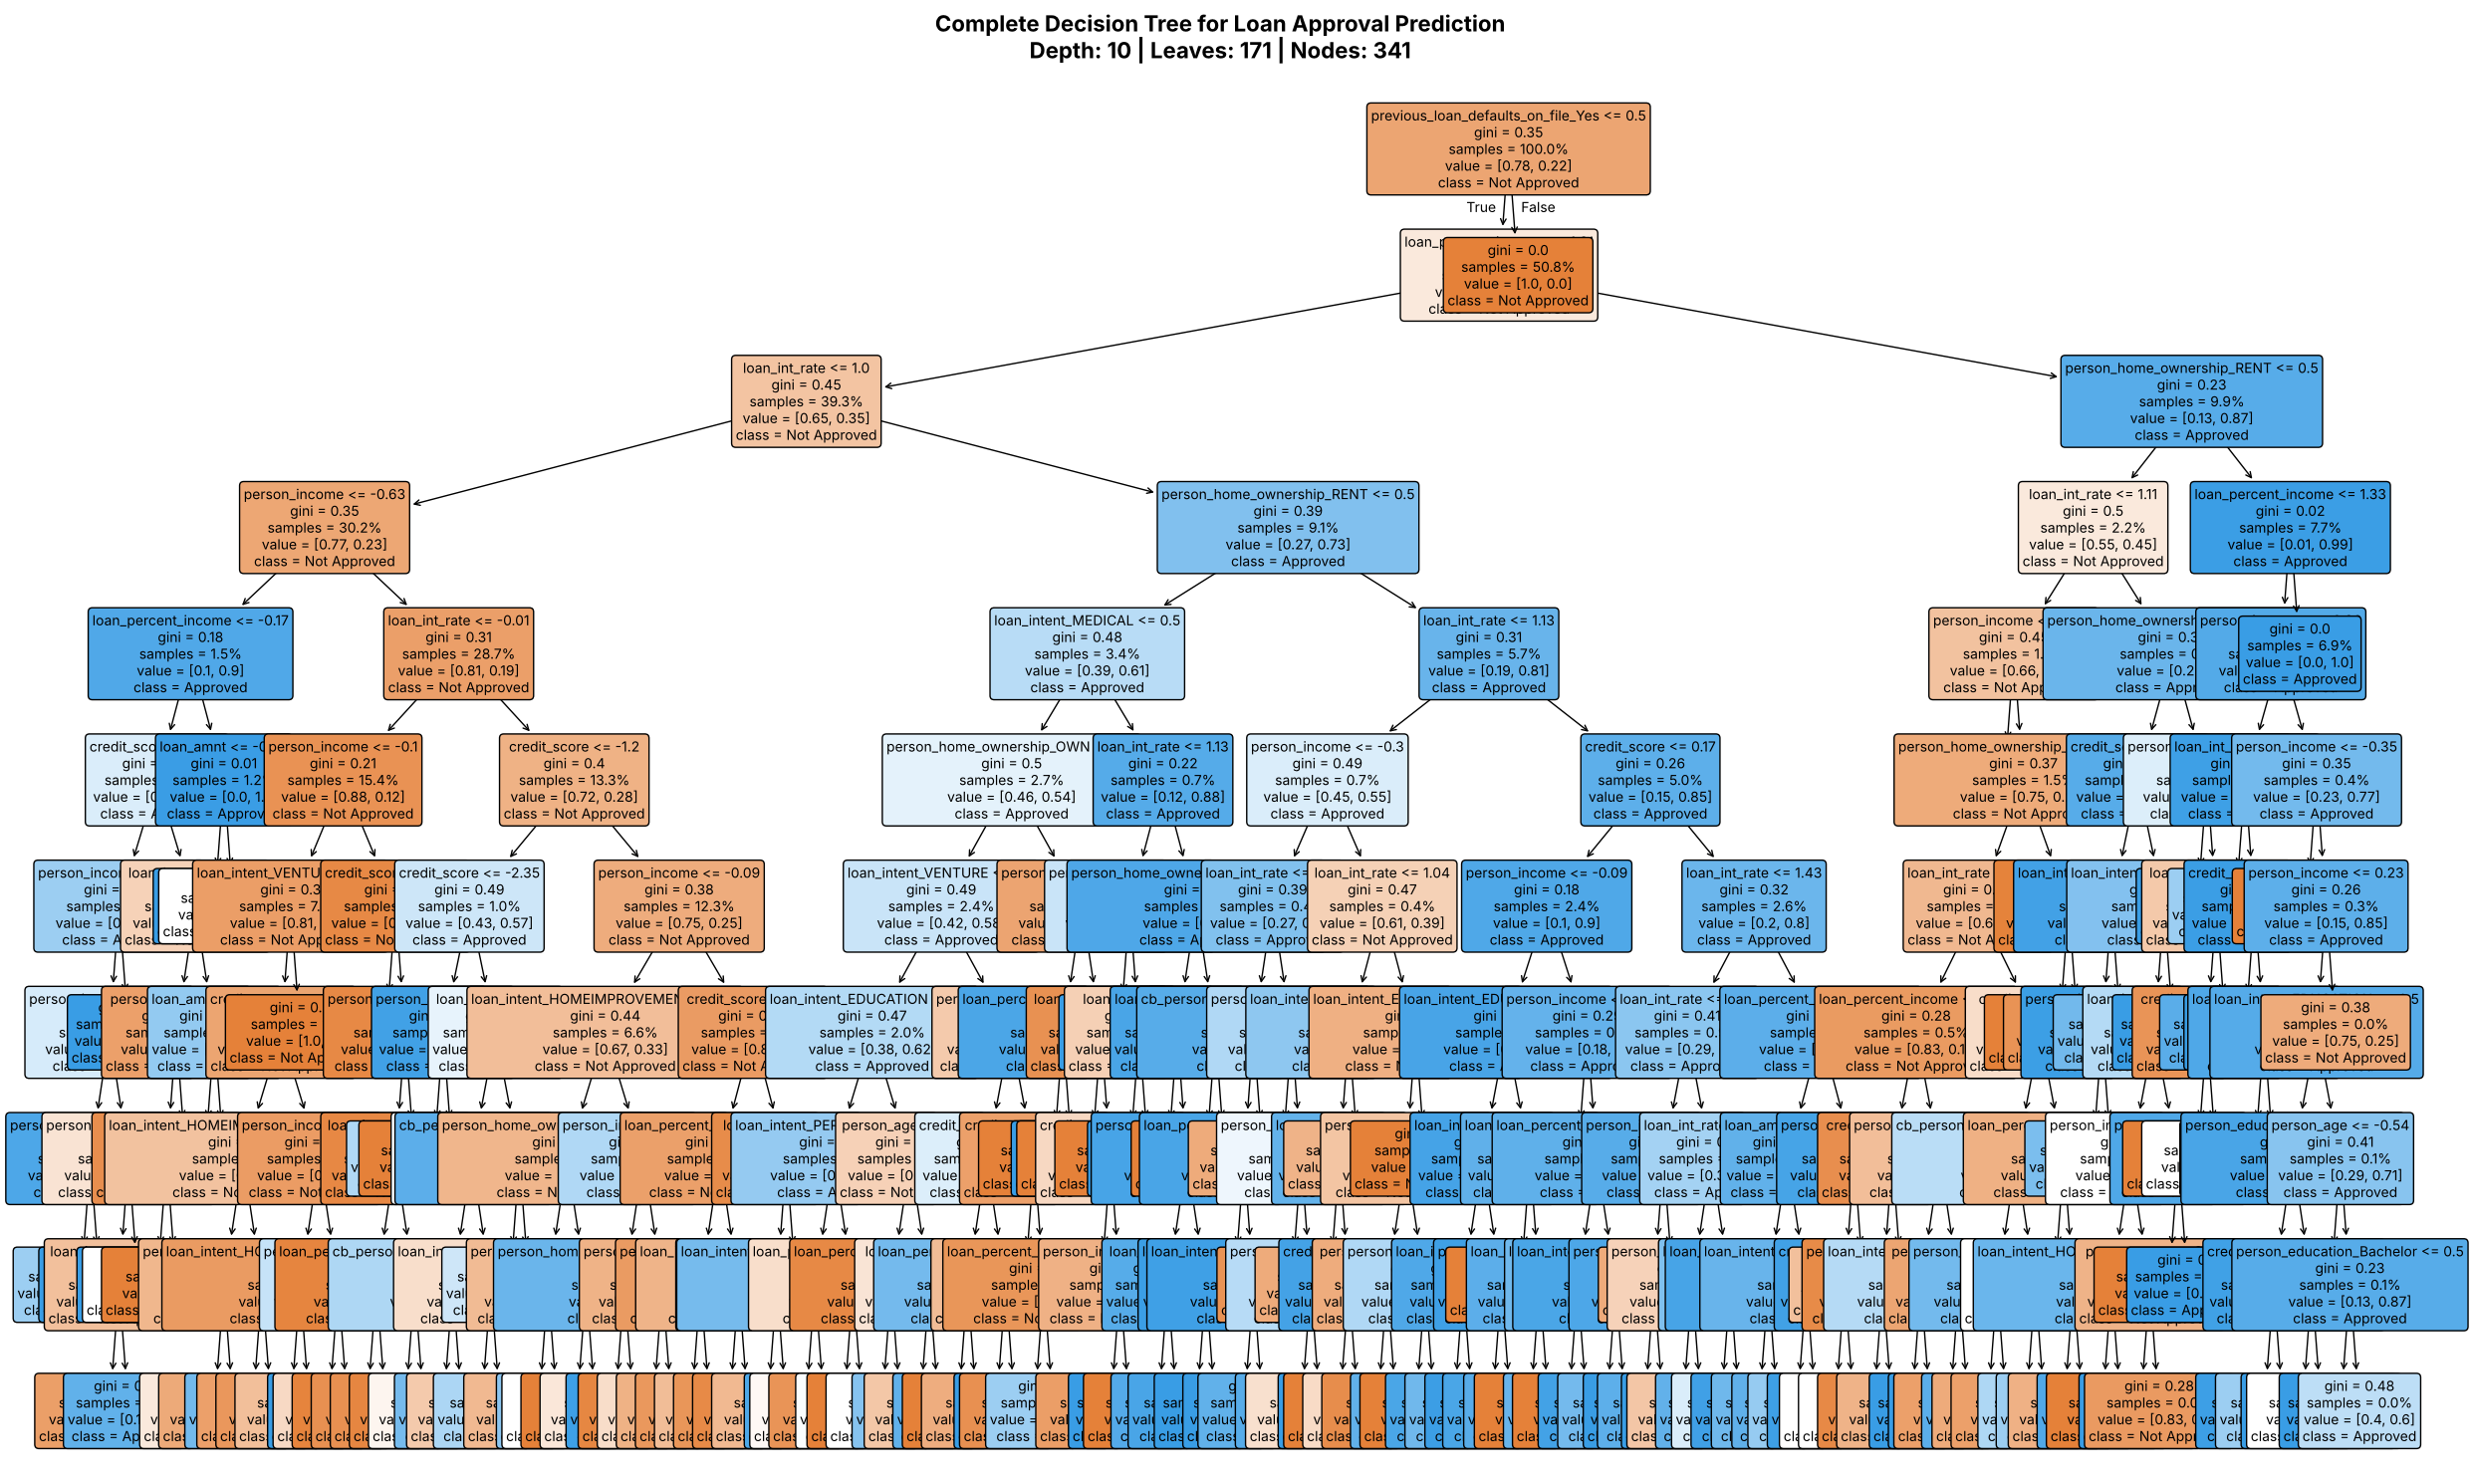


Generating simplified tree visualization (max_depth=3)...


Saved: decision_tree_simplified.png


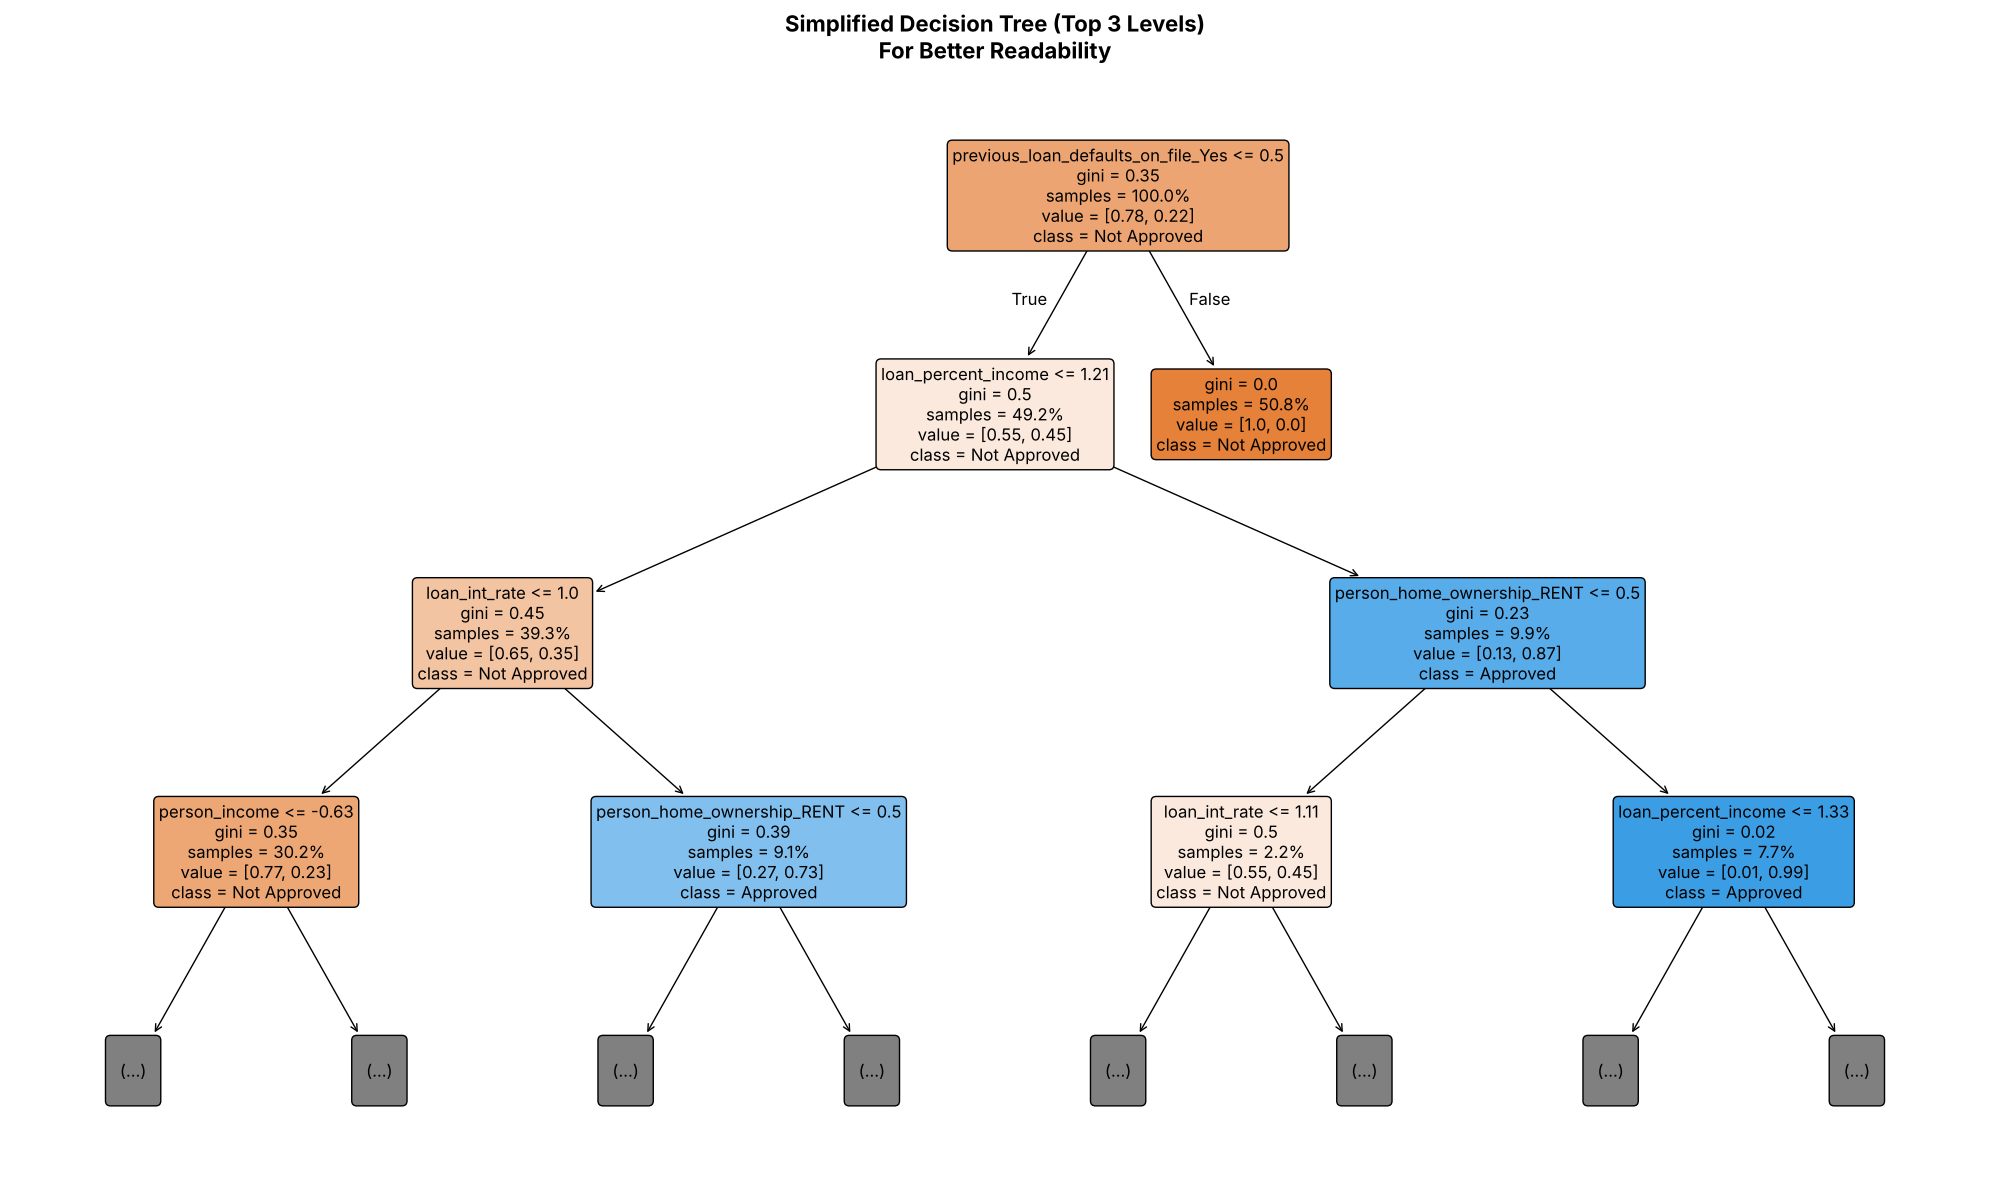


Generating high-resolution tree with model parameters...


Saved: decision_tree_highres.png (high resolution - 600 DPI)


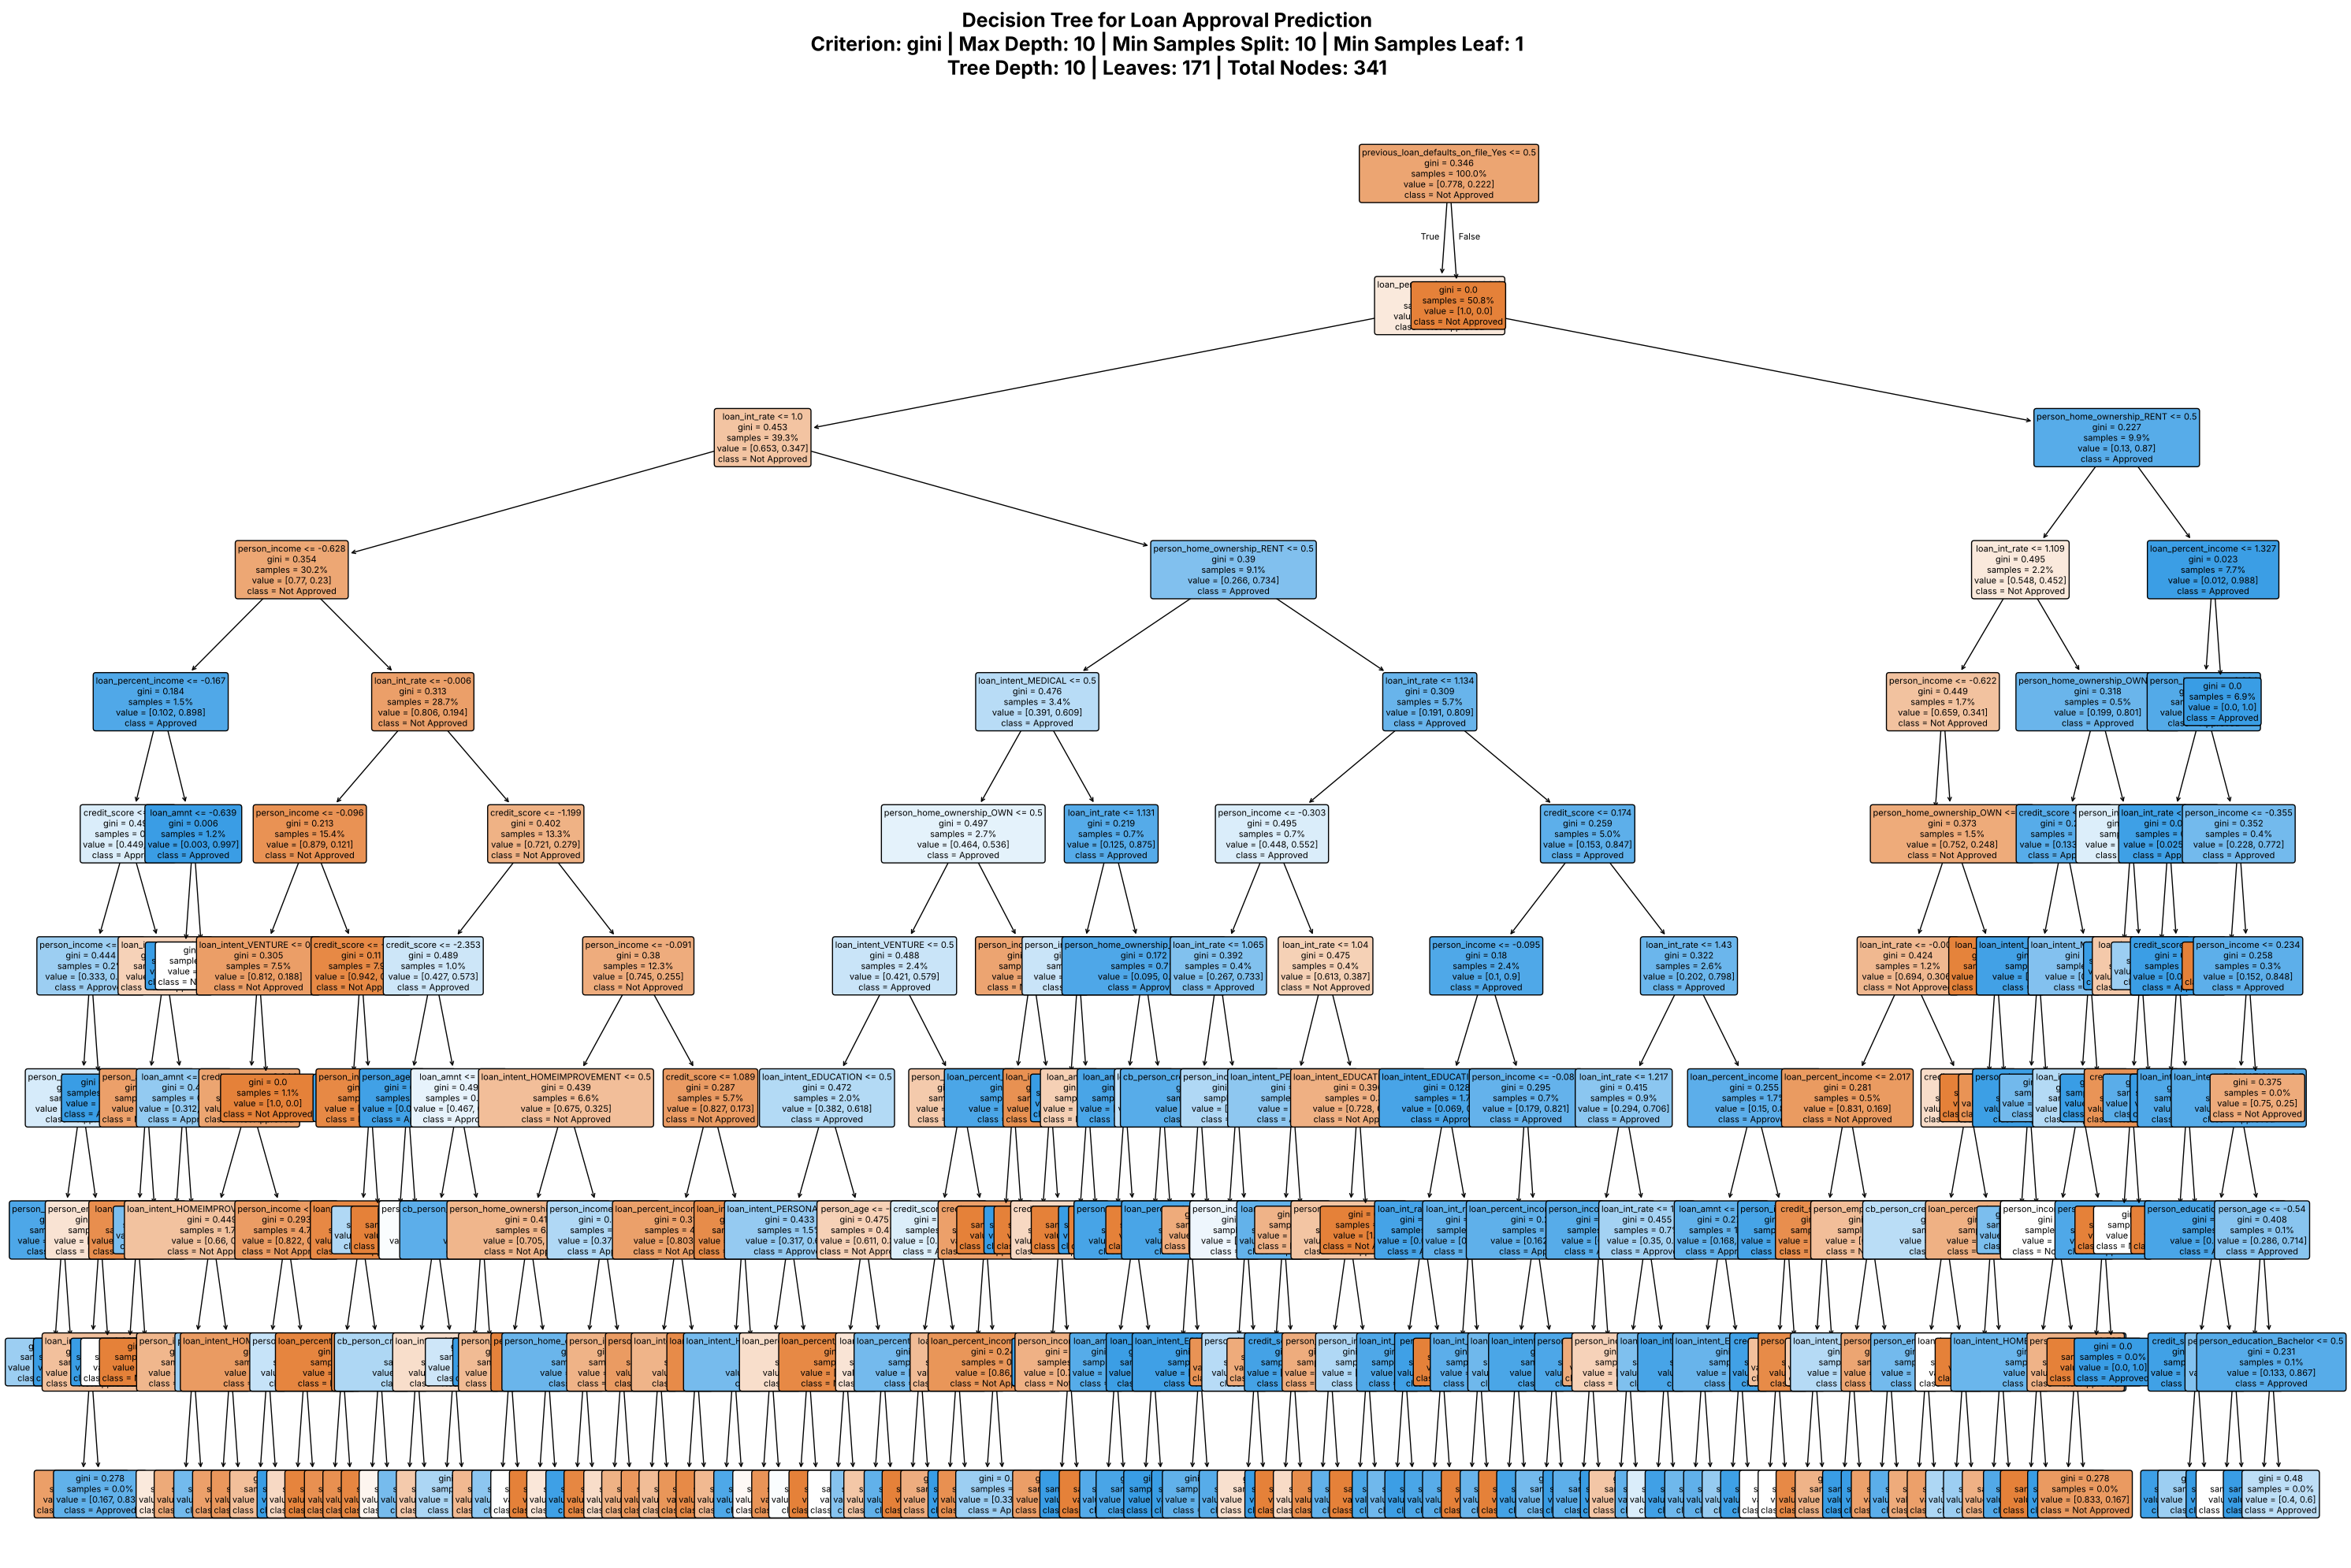


TREE VISUALIZATION COMPLETE!
Generated files:
1. decision_tree_full.png
2. decision_tree_simplified.png
3. decision_tree_highres.png


In [23]:
# Getting tree information
tree_depth = best_model.get_depth()
n_leaves = best_model.get_n_leaves()
n_nodes = best_model.tree_.node_count

print(f"Tree Structure Information:")
print(f"Tree Depth: {tree_depth} levels")
print(f"Number of Leaves: {n_leaves}")
print(f"Total Nodes: {n_nodes}")

# VISUALIZATION 1: Full Decision Tree
print("\nGenerating full decision tree visualization...")
plt.figure(figsize=(25, 15))
plot_tree(
    best_model,
    feature_names=all_feature_names,
    class_names=['Not Approved', 'Approved'],
    filled=True,
    rounded=True,
    fontsize=10,
    proportion=True,
    precision=2
)
plt.title(f'Complete Decision Tree for Loan Approval Prediction\n'
          f'Depth: {tree_depth} | Leaves: {n_leaves} | Nodes: {n_nodes}',
          fontsize=16, pad=20, weight='bold')
plt.tight_layout()
plt.savefig('decision_tree_full.png', dpi=300, bbox_inches='tight')
print("Saved: decision_tree_full.png")
plt.show()

# VISUALIZATION 2: Simplified Tree (Max Depth 3 for readability)
print("\nGenerating simplified tree visualization (max_depth=3)...")
plt.figure(figsize=(20, 12))
plot_tree(
    best_model,
    feature_names=all_feature_names,
    class_names=['Not Approved', 'Approved'],
    filled=True,
    rounded=True,
    fontsize=12,
    max_depth=3,  # Limit depth for readability
    proportion=True,
    precision=2
)
plt.title('Simplified Decision Tree (Top 3 Levels)\nFor Better Readability',
          fontsize=16, pad=20, weight='bold')
plt.tight_layout()
plt.savefig('decision_tree_simplified.png', dpi=300, bbox_inches='tight')
print("Saved: decision_tree_simplified.png")
plt.show()

# VISUALIZATION 3: High-Resolution Tree with Custom Styling
print("\nGenerating high-resolution tree with model parameters...")
fig, ax = plt.subplots(figsize=(30, 20))
plot_tree(
    best_model,
    feature_names=all_feature_names,
    class_names=['Not Approved', 'Approved'],
    filled=True,
    rounded=True,
    fontsize=8,
    ax=ax,
    proportion=True,
    precision=3,
    impurity=True  # Show gini/entropy values
)

# Add custom title with model parameters
title_text = f'Decision Tree for Loan Approval Prediction\n'
title_text += f'Criterion: {best_params["criterion"]} | '
title_text += f'Max Depth: {best_params["max_depth"]} | '
title_text += f'Min Samples Split: {best_params["min_samples_split"]} | '
title_text += f'Min Samples Leaf: {best_params["min_samples_leaf"]}\n'
title_text += f'Tree Depth: {tree_depth} | Leaves: {n_leaves} | Total Nodes: {n_nodes}'

ax.set_title(title_text, fontsize=18, pad=30, weight='bold')

plt.tight_layout()
plt.savefig('decision_tree_highres.png', dpi=600, bbox_inches='tight')
print("Saved: decision_tree_highres.png (high resolution - 600 DPI)")
plt.show()

print("\n" + "="*60)
print("TREE VISUALIZATION COMPLETE!")
print("="*60)
print("Generated files:")
print("1. decision_tree_full.png")
print("2. decision_tree_simplified.png")
print("3. decision_tree_highres.png")

## 16. Cost-Complexity Pruning

The grid-searched tree controls complexity indirectly, through `max_depth` and the minimum sample sizes, and ends up with 171 leaves. Minimal cost-complexity pruning controls it directly: it grows a full tree, then removes the branches whose improvement in training impurity is too small to justify their size. Each value of the complexity parameter `ccp_alpha` gives a nested, smaller subtree.

**How the pruned tree is chosen.** Every distinct `ccp_alpha` on the pruning path is scored with the same 3-fold stratified cross-validation used for the grid search, on F1 for the approved class. Two selection rules are applied, using cross-validation only:

1. **Best pruned tree:** the alpha with the highest cross-validated F1.
2. **Compact pruned tree:** the smallest tree whose cross-validated F1 is within 0.01 (one F1 point) of the best. This deliberately trades a small, bounded amount of F1 for readability.

The validation and test sets are used only to report results, never to choose alpha.

In [24]:
import time
from sklearn.model_selection import cross_validate

# Grow an unrestricted tree on the training data and compute its pruning path.
# Larger ccp_alpha values give smaller subtrees of the same full tree.
full_tree = DecisionTreeClassifier(criterion='gini', random_state=42).fit(X_train_processed, y_train)
pruning_path = full_tree.cost_complexity_pruning_path(X_train_processed, y_train)
candidate_alphas = np.unique(pruning_path.ccp_alphas[:-1])  # the last alpha prunes the tree to a single node

print("COST-COMPLEXITY PRUNING PATH")
print("-" * 60)
print(f"Unpruned tree: depth {full_tree.get_depth()}, {full_tree.get_n_leaves()} leaves")
print(f"Distinct alphas on the pruning path: {len(candidate_alphas)}")
print("Scoring every alpha with 3-fold stratified CV (F1 on the approved class). This takes a few minutes...")

start_time = time.time()
ccp_rows = []
for alpha in candidate_alphas:
    cv_scores = cross_validate(
        DecisionTreeClassifier(criterion='gini', ccp_alpha=alpha, random_state=42),
        X_train_processed, y_train, cv=cv_strategy, scoring='f1', n_jobs=-1
    )
    pruned_tree = DecisionTreeClassifier(criterion='gini', ccp_alpha=alpha, random_state=42).fit(X_train_processed, y_train)
    ccp_rows.append({
        'ccp_alpha': alpha,
        'cv_f1': cv_scores['test_score'].mean(),
        'cv_f1_std': cv_scores['test_score'].std(),
        'n_leaves': pruned_tree.get_n_leaves(),
        'depth': pruned_tree.get_depth(),
    })

ccp_results = pd.DataFrame(ccp_rows)
print(f"Completed in {time.time() - start_time:.0f} seconds")

COST-COMPLEXITY PRUNING PATH
------------------------------------------------------------
Unpruned tree: depth 34, 1799 leaves
Distinct alphas on the pruning path: 543
Scoring every alpha with 3-fold stratified CV (F1 on the approved class). This takes a few minutes...


Completed in 201 seconds


In [25]:
F1_TOLERANCE = 0.01  # largest drop in CV F1 accepted in exchange for a smaller tree

# Rule 1: best cross-validated F1
best_idx = ccp_results['cv_f1'].idxmax()
alpha_best = ccp_results.loc[best_idx, 'ccp_alpha']
best_pruned_cv_f1 = ccp_results.loc[best_idx, 'cv_f1']

# Rule 2: smallest tree (largest alpha) within the tolerance of the best
within_tolerance = ccp_results[ccp_results['cv_f1'] >= best_pruned_cv_f1 - F1_TOLERANCE]
compact_idx = within_tolerance['ccp_alpha'].idxmax()
alpha_compact = ccp_results.loc[compact_idx, 'ccp_alpha']

pruned_best = DecisionTreeClassifier(criterion='gini', ccp_alpha=alpha_best, random_state=42).fit(X_train_processed, y_train)
pruned_compact = DecisionTreeClassifier(criterion='gini', ccp_alpha=alpha_compact, random_state=42).fit(X_train_processed, y_train)

print("SELECTED PRUNED TREES")
print("-" * 60)
print(f"Grid-search tree (Section 7): {best_model.get_n_leaves()} leaves, depth {best_model.get_depth()}, CV F1 {grid_search.best_score_:.4f}")
print(f"Best pruned tree:    ccp_alpha = {alpha_best:.6f}, {pruned_best.get_n_leaves()} leaves, "
      f"depth {pruned_best.get_depth()}, CV F1 {best_pruned_cv_f1:.4f}")
print(f"Compact pruned tree: ccp_alpha = {alpha_compact:.6f}, {pruned_compact.get_n_leaves()} leaves, "
      f"depth {pruned_compact.get_depth()}, CV F1 {ccp_results.loc[compact_idx, 'cv_f1']:.4f}")

# How much F1 does each leaf budget buy? Best CV F1 among pruned trees with at most N leaves.
print("\nBest cross-validated F1 for a given maximum number of leaves:")
budget_rows = []
for budget in [5, 10, 15, 20, 30, 50, 75, 100, 171]:
    eligible = ccp_results[ccp_results['n_leaves'] <= budget]
    row = eligible.loc[eligible['cv_f1'].idxmax()]
    budget_rows.append({'max_leaves': budget, 'leaves': int(row['n_leaves']), 'depth': int(row['depth']),
                        'cv_f1': round(row['cv_f1'], 4)})
print(pd.DataFrame(budget_rows).to_string(index=False))

SELECTED PRUNED TREES
------------------------------------------------------------
Grid-search tree (Section 7): 171 leaves, depth 10, CV F1 0.8029
Best pruned tree:    ccp_alpha = 0.000227, 62 leaves, depth 17, CV F1 0.8108
Compact pruned tree: ccp_alpha = 0.000738, 18 leaves, depth 8, CV F1 0.8016

Best cross-validated F1 for a given maximum number of leaves:
 max_leaves  leaves  depth  cv_f1
          5       5      4 0.7729
         10      10      6 0.7814
         15      15      8 0.7944
         20      20      9 0.8016
         30      30     10 0.8064
         50      49     17 0.8096
         75      62     17 0.8108
        100      62     17 0.8108
        171      62     17 0.8108


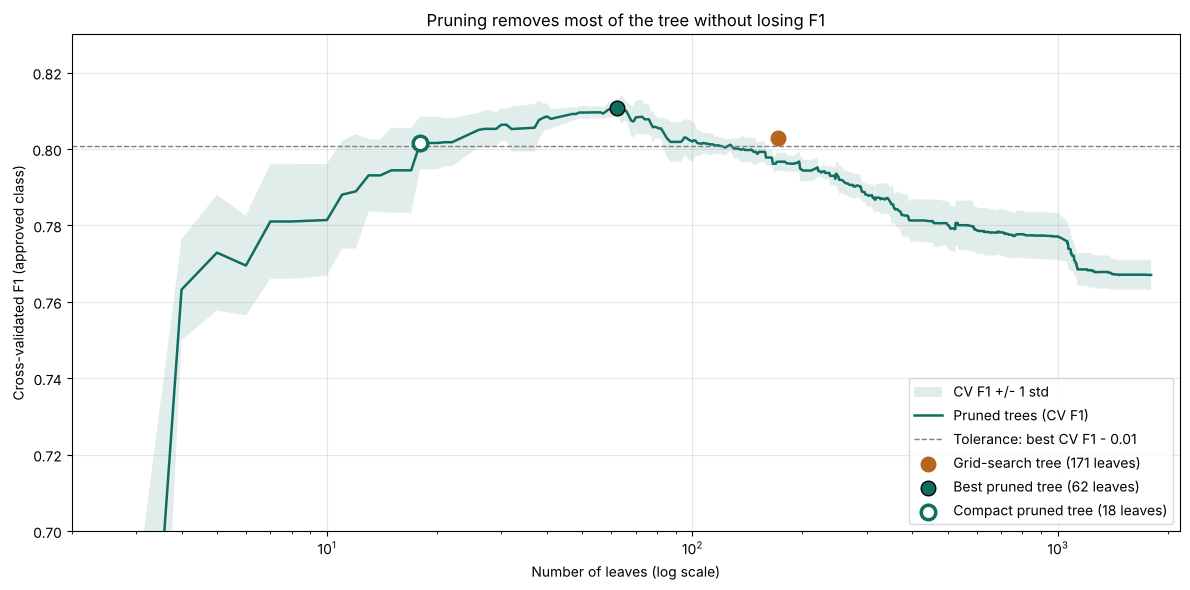

In [26]:
# Cross-validated F1 against tree size along the pruning path
curve = ccp_results.sort_values('n_leaves')
compact_leaves = pruned_compact.get_n_leaves()
best_leaves = pruned_best.get_n_leaves()

fig, ax = plt.subplots(figsize=(12, 6))
ax.fill_between(curve['n_leaves'], curve['cv_f1'] - curve['cv_f1_std'], curve['cv_f1'] + curve['cv_f1_std'],
                color='#0F6E5F', alpha=0.12, linewidth=0, label='CV F1 +/- 1 std')
ax.plot(curve['n_leaves'], curve['cv_f1'], color='#0F6E5F', linewidth=1.8, label='Pruned trees (CV F1)')
ax.axhline(best_pruned_cv_f1 - F1_TOLERANCE, color='grey', linestyle='--', linewidth=1,
           label=f'Tolerance: best CV F1 - {F1_TOLERANCE}')

ax.scatter([best_model.get_n_leaves()], [grid_search.best_score_], s=110, color='#B5651D', zorder=5,
           label=f'Grid-search tree ({best_model.get_n_leaves()} leaves)')
ax.scatter([best_leaves], [best_pruned_cv_f1], s=110, color='#0F6E5F', edgecolor='black', zorder=5,
           label=f'Best pruned tree ({best_leaves} leaves)')
ax.scatter([compact_leaves], [ccp_results.loc[compact_idx, 'cv_f1']], s=110, color='white', edgecolor='#0F6E5F',
           linewidth=2.5, zorder=5, label=f'Compact pruned tree ({compact_leaves} leaves)')

ax.set_xscale('log')
ax.set_xlim(2, full_tree.get_n_leaves() * 1.2)
ax.set_ylim(0.70, 0.83)
ax.set_xlabel('Number of leaves (log scale)')
ax.set_ylabel('Cross-validated F1 (approved class)')
ax.set_title('Pruning removes most of the tree without losing F1')
ax.grid(True, alpha=0.3)
ax.legend(loc='lower right')
plt.tight_layout()
plt.show()

In [27]:
# Compare the grid-search tree with both pruned trees on validation and test data
def tree_summary(model, name, cv_f1):
    val_pred = model.predict(X_val_processed)
    test_pred = model.predict(X_test_processed)
    test_proba = model.predict_proba(X_test_processed)[:, 1]
    tn, fp, fn, tp = confusion_matrix(y_test, test_pred).ravel()
    return {
        'Model': name,
        'Leaves': model.get_n_leaves(),
        'Depth': model.get_depth(),
        'CV F1': round(cv_f1, 4),
        'Val F1': round(f1_score(y_val, val_pred), 4),
        'Test precision': round(precision_score(y_test, test_pred), 4),
        'Test recall': round(recall_score(y_test, test_pred), 4),
        'Test F1': round(f1_score(y_test, test_pred), 4),
        'Test ROC-AUC': round(roc_auc_score(y_test, test_proba), 4),
        'Test PR-AUC': round(average_precision_score(y_test, test_proba), 4),
        'Test accuracy': round(accuracy_score(y_test, test_pred), 4),
        'Wrong approvals (FP)': fp,
        'Missed approvals (FN)': fn,
    }

comparison_df = pd.DataFrame([
    tree_summary(best_model, 'Grid-search tree', grid_search.best_score_),
    tree_summary(pruned_best, 'Best pruned tree', best_pruned_cv_f1),
    tree_summary(pruned_compact, 'Compact pruned tree', ccp_results.loc[compact_idx, 'cv_f1']),
]).set_index('Model')

count_columns = ['Leaves', 'Depth', 'Wrong approvals (FP)', 'Missed approvals (FN)']
display_df = comparison_df.copy()
for col in display_df.columns:
    display_df[col] = display_df[col].map(lambda v: f"{int(v):,}" if col in count_columns else f"{v:.4f}")

print("GRID-SEARCH TREE VS PRUNED TREES (test set: 9,000 applications)")
print("-" * 70)
print(display_df.T.to_string())

GRID-SEARCH TREE VS PRUNED TREES (test set: 9,000 applications)
----------------------------------------------------------------------
Model                 Grid-search tree Best pruned tree Compact pruned tree
Leaves                             171               62                  18
Depth                               10               17                   8
CV F1                           0.8029           0.8108              0.8016
Val F1                          0.7874           0.7949              0.7880
Test precision                  0.8938           0.8711              0.8273
Test recall                     0.7240           0.7570              0.7665
Test F1                         0.8000           0.8101              0.7957
Test ROC-AUC                    0.9586           0.9676              0.9616
Test PR-AUC                     0.8814           0.9060              0.8775
Test accuracy                   0.9196           0.9211              0.9126
Wrong approvals (FP)         

### 16.1 The compact pruned tree in original units

The model was trained on standardized features, so its split thresholds are in standard-deviation units. For reading only, the cell below makes a copy of the compact tree, converts each numeric threshold back to the original units (for example, a loan-to-income ratio of 0.25 instead of a z-score), and draws the whole tree. The copy is used for display only; all predictions use the trained model.

Saved: decision_tree_pruned_compact.png


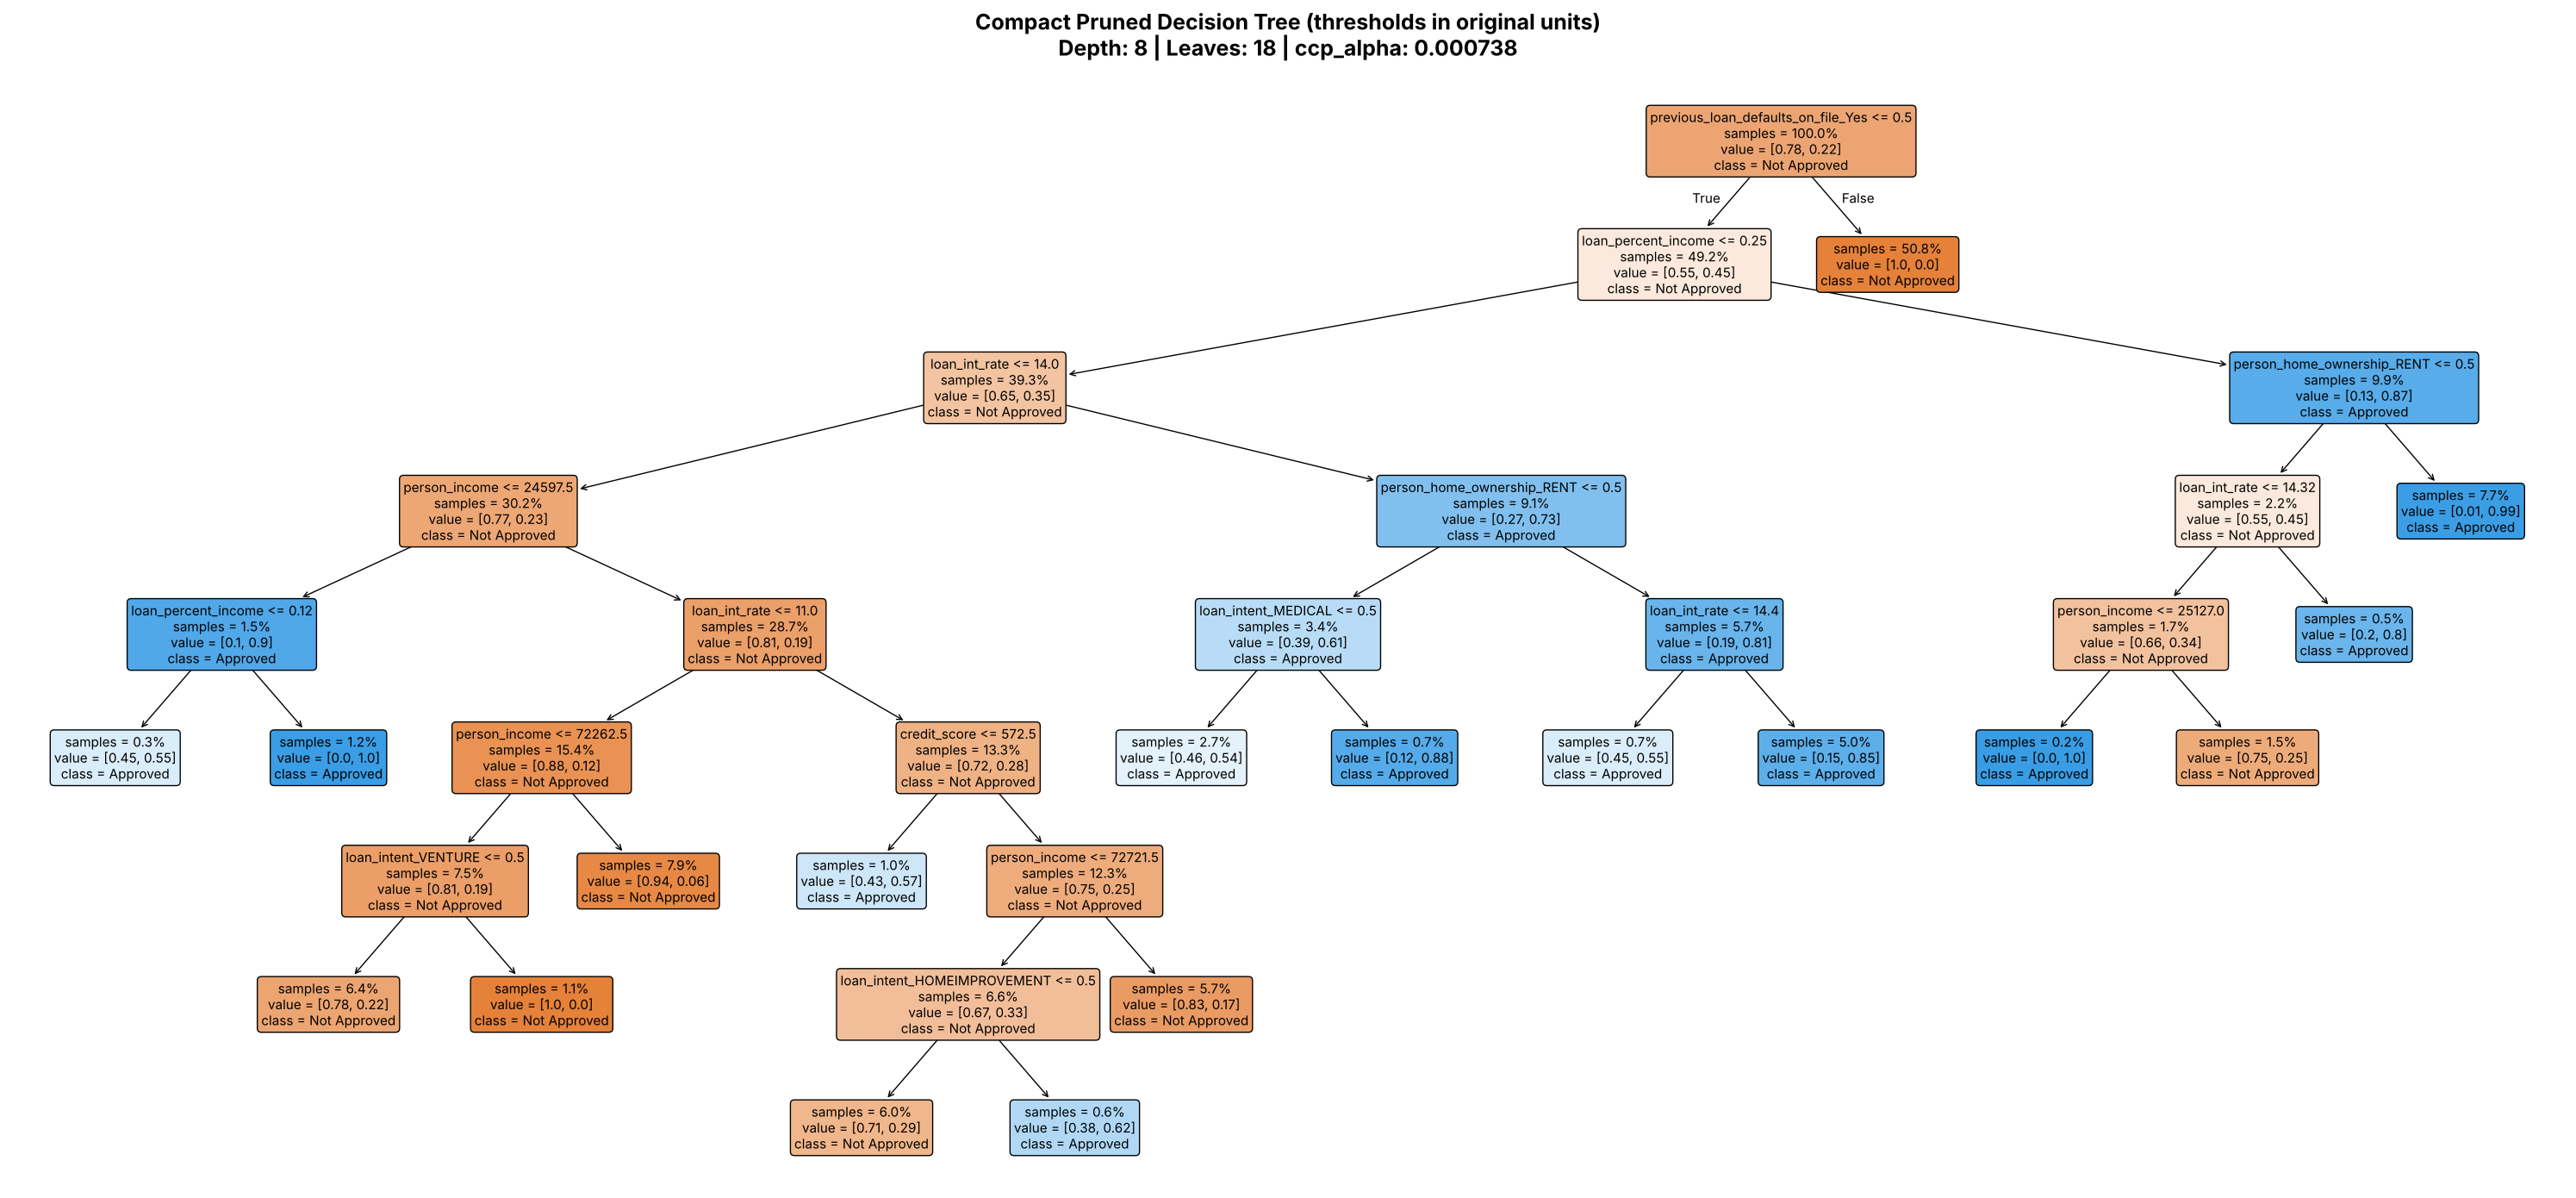

In [28]:
import copy
from sklearn.tree import export_text

num_scaler = preprocessor.named_transformers_['num']
n_numeric = len(numerical_cols)

def to_original_units(model):
    """Copy of a fitted tree whose numeric thresholds are in original units (display only)."""
    display_model = copy.deepcopy(model)
    tree = display_model.tree_
    for node in range(tree.node_count):
        feature = tree.feature[node]
        if 0 <= feature < n_numeric:  # numeric columns come first in the preprocessor output
            tree.threshold[node] = tree.threshold[node] * num_scaler.scale_[feature] + num_scaler.mean_[feature]
    return display_model

compact_display = to_original_units(pruned_compact)

plt.figure(figsize=(30, 14))
plot_tree(
    compact_display,
    feature_names=all_feature_names,
    class_names=['Not Approved', 'Approved'],
    filled=True,
    rounded=True,
    fontsize=11,
    proportion=True,
    precision=2,
    impurity=False
)
plt.title(f'Compact Pruned Decision Tree (thresholds in original units)\n'
          f'Depth: {pruned_compact.get_depth()} | Leaves: {pruned_compact.get_n_leaves()} | ccp_alpha: {alpha_compact:.6f}',
          fontsize=18, pad=20, weight='bold')
plt.tight_layout()
plt.savefig('decision_tree_pruned_compact.png', dpi=200, bbox_inches='tight')
print("Saved: decision_tree_pruned_compact.png")
plt.show()

In [29]:
# The compact tree as plain if-then rules, thresholds in original units.
# Sibling branches that reach the same decision are merged, so each rule is one distinct decision region.
# Merging changes nothing about the predictions; it only removes splits that do not change the outcome.
display_tree = compact_display.tree_
n_train_samples = display_tree.n_node_samples[0]
class_labels = ['Not Approved', 'Approved']

def readable_condition(feature_idx, threshold, goes_left):
    name = all_feature_names[feature_idx]
    if feature_idx < n_numeric:
        return f"{name} {'<=' if goes_left else '>'} {threshold:,.2f}"
    for col in categorical_cols:  # one-hot columns are named <column>_<category>
        if name.startswith(col + '_'):
            return f"{col} {'is not' if goes_left else 'is'} {name[len(col) + 1:]}"
    return f"{name} {'<=' if goes_left else '>'} {threshold:.2f}"

def uniform_decision(node):
    """Predicted class if every leaf below this node predicts the same class, else None."""
    if display_tree.children_left[node] == -1:
        return int(np.argmax(display_tree.value[node][0]))
    left = uniform_decision(display_tree.children_left[node])
    right = uniform_decision(display_tree.children_right[node])
    return left if (left is not None and left == right) else None

decision_rules = []
def collect_rules(node, conditions):
    decision = uniform_decision(node)
    if decision is not None:
        counts = display_tree.value[node][0]
        decision_rules.append({'conditions': conditions, 'decision': class_labels[decision],
                               'share_of_applicants': display_tree.n_node_samples[node] / n_train_samples,
                               'approved_share': counts[1] / counts.sum()})
        return
    feature, threshold = display_tree.feature[node], display_tree.threshold[node]
    collect_rules(display_tree.children_left[node], conditions + [readable_condition(feature, threshold, True)])
    collect_rules(display_tree.children_right[node], conditions + [readable_condition(feature, threshold, False)])

collect_rules(0, [])

print("COMPACT PRUNED TREE AS DECISION RULES")
print("-" * 60)
print(f"{pruned_compact.get_n_leaves()} leaves reduce to {len(decision_rules)} decision rules with identical predictions.\n")
for i, rule in enumerate(decision_rules, 1):
    print(f"Rule {i}: IF " + "\n         AND ".join(rule['conditions']))
    print(f"        THEN {rule['decision'].upper()}   "
          f"({rule['share_of_applicants']:.1%} of training applicants, {rule['approved_share']:.0%} approved)\n")

COMPACT PRUNED TREE AS DECISION RULES
------------------------------------------------------------
18 leaves reduce to 12 decision rules with identical predictions.

Rule 1: IF previous_loan_defaults_on_file is not Yes
         AND loan_percent_income <= 0.25
         AND loan_int_rate <= 14.00
         AND person_income <= 24,597.50
        THEN APPROVED   (1.5% of training applicants, 90% approved)

Rule 2: IF previous_loan_defaults_on_file is not Yes
         AND loan_percent_income <= 0.25
         AND loan_int_rate <= 14.00
         AND person_income > 24,597.50
         AND loan_int_rate <= 11.00
        THEN NOT APPROVED   (15.4% of training applicants, 12% approved)

Rule 3: IF previous_loan_defaults_on_file is not Yes
         AND loan_percent_income <= 0.25
         AND loan_int_rate <= 14.00
         AND person_income > 24,597.50
         AND loan_int_rate > 11.00
         AND credit_score <= 572.50
        THEN APPROVED   (1.0% of training applicants, 57% approved)

Rule 4:

In [30]:
# Feature importance: grid-search tree vs compact pruned tree
importance_compare = pd.DataFrame({
    'feature': all_feature_names,
    'grid_search_tree': best_model.feature_importances_,
    'compact_pruned_tree': pruned_compact.feature_importances_,
}).sort_values('compact_pruned_tree', ascending=False)

used = (pruned_compact.feature_importances_ > 0).sum()
print("FEATURE IMPORTANCE: GRID-SEARCH TREE VS COMPACT PRUNED TREE")
print("-" * 60)
print(importance_compare.head(8).round(4).to_string(index=False))
print(f"\nFeatures used by the compact pruned tree: {used} of {len(all_feature_names)}")
print(f"Features used by the grid-search tree:    {(best_model.feature_importances_ > 0).sum()} of {len(all_feature_names)}")

FEATURE IMPORTANCE: GRID-SEARCH TREE VS COMPACT PRUNED TREE
------------------------------------------------------------
                           feature  grid_search_tree  compact_pruned_tree
previous_loan_defaults_on_file_Yes            0.4114               0.4551
               loan_percent_income            0.1835               0.1972
                     loan_int_rate            0.1832               0.1874
                     person_income            0.1026               0.0852
        person_home_ownership_RENT            0.0484               0.0514
                      credit_score            0.0198               0.0084
               loan_intent_MEDICAL            0.0066               0.0058
       loan_intent_HOMEIMPROVEMENT            0.0117               0.0054

Features used by the compact pruned tree: 9 of 22
Features used by the grid-search tree:    19 of 22


In [31]:
import pickle

with open('decision_tree_pruned_compact.pkl', 'wb') as f:
    pickle.dump(pruned_compact, f)
with open('decision_tree_pruned_best.pkl', 'wb') as f:
    pickle.dump(pruned_best, f)
print("Saved: decision_tree_pruned_compact.pkl")
print("Saved: decision_tree_pruned_best.pkl")

Saved: decision_tree_pruned_compact.pkl
Saved: decision_tree_pruned_best.pkl


In [32]:
# Summary of what pruning changed
g, b, c = comparison_df.loc['Grid-search tree'], comparison_df.loc['Best pruned tree'], comparison_df.loc['Compact pruned tree']

print("PRUNING SUMMARY")
print("=" * 60)
print(f"Grid-search tree:    {int(g['Leaves']):>4} leaves, depth {int(g['Depth']):>2}, test F1 {g['Test F1']:.3f}, test ROC-AUC {g['Test ROC-AUC']:.3f}")
print(f"Best pruned tree:    {int(b['Leaves']):>4} leaves, depth {int(b['Depth']):>2}, test F1 {b['Test F1']:.3f}, test ROC-AUC {b['Test ROC-AUC']:.3f}")
print(f"Compact pruned tree: {int(c['Leaves']):>4} leaves, depth {int(c['Depth']):>2}, test F1 {c['Test F1']:.3f}, test ROC-AUC {c['Test ROC-AUC']:.3f}")

print(f"\nCompact tree vs grid-search tree:")
print(f"- {g['Leaves'] / c['Leaves']:.0f}x fewer leaves ({int(c['Leaves'])} instead of {int(g['Leaves'])}), "
      f"which merge into {len(decision_rules)} decision rules")
print(f"- Test F1 {c['Test F1'] - g['Test F1']:+.3f}, test ROC-AUC {c['Test ROC-AUC'] - g['Test ROC-AUC']:+.3f}")
print(f"- Wrong approvals {int(c['Wrong approvals (FP)'])} vs {int(g['Wrong approvals (FP)'])}; "
      f"missed approvals {int(c['Missed approvals (FN)'])} vs {int(g['Missed approvals (FN)'])}")
print(f"\nBest pruned tree vs grid-search tree:")
print(f"- {g['Leaves'] / b['Leaves']:.1f}x fewer leaves, test F1 {b['Test F1'] - g['Test F1']:+.3f}, "
      f"test ROC-AUC {b['Test ROC-AUC'] - g['Test ROC-AUC']:+.3f}")

PRUNING SUMMARY
Grid-search tree:     171 leaves, depth 10, test F1 0.800, test ROC-AUC 0.959
Best pruned tree:      62 leaves, depth 17, test F1 0.810, test ROC-AUC 0.968
Compact pruned tree:   18 leaves, depth  8, test F1 0.796, test ROC-AUC 0.962

Compact tree vs grid-search tree:
- 10x fewer leaves (18 instead of 171), which merge into 12 decision rules
- Test F1 -0.004, test ROC-AUC +0.003
- Wrong approvals 320 vs 172; missed approvals 467 vs 552

Best pruned tree vs grid-search tree:
- 2.8x fewer leaves, test F1 +0.010, test ROC-AUC +0.009


### 16.2 Takeaway

- **Pruning beats the depth-limited grid search.** The best pruned tree reaches a higher cross-validated F1 than the grid-search tree with about a third of the leaves, and it also scores higher on the test set.
- **The compact tree buys readability almost for free.** Within one F1 point of the best, it has about a tenth of the grid-search tree's leaves and reduces to a short list of if-then rules a credit officer can read in full.
- **The error mix shifts.** At the default 0.5 threshold, both pruned trees approve more readily than the grid-search tree: fewer missed approvals, more wrong approvals. Which tree to deploy, and at what threshold, depends on how much more a wrong approval costs the lender than a missed one.